# Lab 13: Numerical Differentiation

Derivatives are fundamental to science and engineering — from computing velocity from position data to evaluating sensitivities in optimization. When an **analytic derivative is unavailable** or the function is known only at **discrete data points**, we must estimate derivatives numerically.

Two complementary approaches are covered in this lab:

- **Finite Difference Method (FDM)** — approximates derivatives using function values at nearby points via Taylor expansion.
- **Finite Element Derivative Recovery** — uses the FEM framework (basis functions + projection) to obtain smoother, higher-accuracy derivative estimates from discrete nodal data.

## Learning Objectives

By the end of this session, you will be able to:
- Derive **forward, backward, and central difference** formulas and explain their truncation errors
- Implement **second-order and higher-order FD stencils** for 1st and 2nd derivatives
- Apply **Richardson extrapolation** to boost accuracy without extra function evaluations
- Explain the **subtractive cancellation** problem and choose the optimal step size $h$
- Use the **complex-step method** to bypass cancellation error entirely
- Compute **numerical Jacobians and Hessians** for multivariate functions
- Recover derivatives from FEM nodal data using **L2 projection** and **Superconvergent Patch Recovery (SPR)**
- Compare FDM and FEM derivative strategies for accuracy and robustness

## Session Outline

| # | Topic |  
|---|-------| 
| 1 | Benchmark Function & Taylor Expansion Review |  
| 2 | Forward, Backward, and Central Differences |  
| 3 | Higher-Order Stencils & Richardson Extrapolation |  
| 4 | Second Derivatives & Higher-Order Derivatives |  
| 5 | Step Size Selection & Complex-Step Method |  
| 6 | Multivariate Differentiation: Jacobians & Hessians |  
| 7 | FEM Derivative Recovery |  
| 8 | Engineering Applications |  

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve
import warnings
warnings.filterwarnings('ignore')

---
## 1. Benchmark Function and Taylor Expansion Review

### 1.1 Benchmark Function

We use the same polynomial as in the textbook (Chapra & Canale):

$$f(x) = 0.1x^5 - 0.2x^4 + 3.0x^3 + 2.0x^2 - x + 0.5$$

with analytic derivatives:

$$f'(x) = 0.5x^4 - 0.8x^3 + 9.0x^2 + 4.0x - 1$$

$$f''(x) = 2x^3 - 2.4x^2 + 18x + 4$$

$$f'''(x) = 6x^2 - 4.8x + 18$$

### 1.2 Taylor Expansion — Foundation of FDM

Every finite difference formula comes from Taylor's theorem:

$$f(x+h) = f(x) + h f'(x) + \frac{h^2}{2!} f''(x) + \frac{h^3}{3!} f'''(x) + \cdots$$

$$f(x-h) = f(x) - h f'(x) + \frac{h^2}{2!} f''(x) - \frac{h^3}{3!} f'''(x) + \cdots$$

By **rearranging** these expansions, we can isolate $f'(x)$, $f''(x)$, etc., with controlled truncation error.

Benchmark at x = 0.5:
  f(0.5)    = 0.86562500
  f'(0.5)   = 3.18125000
  f''(0.5)  = 12.65000000
  f'''(0.5) = 17.10000000


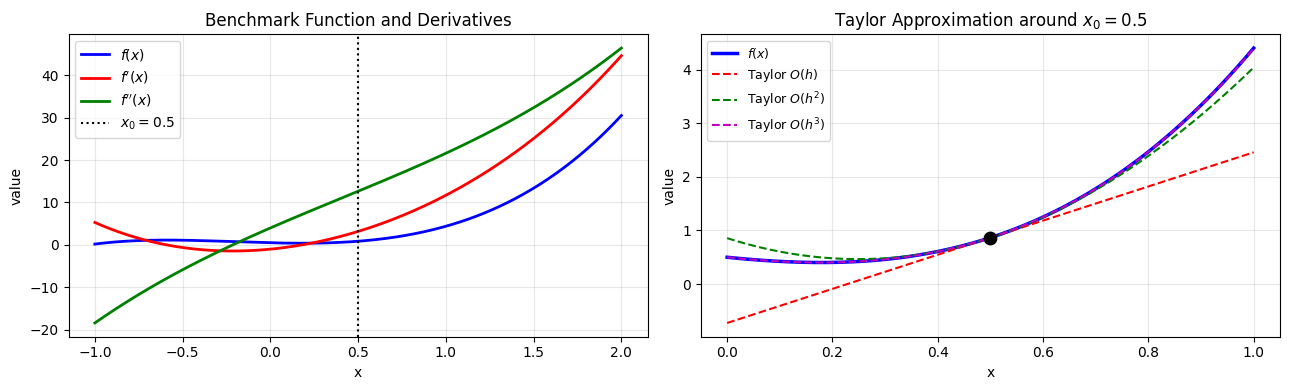

In [2]:
# Benchmark function and its analytic derivatives
f    = lambda x: 0.1*x**5 - 0.2*x**4 + 3.0*x**3 + 2.0*x**2 - x + 0.5
df   = lambda x: 0.5*x**4 - 0.8*x**3 + 9.0*x**2 + 4.0*x - 1.0
d2f  = lambda x: 2.0*x**3 - 2.4*x**2 + 18.0*x + 4.0
d3f  = lambda x: 6.0*x**2 - 4.8*x + 18.0

# Evaluation point and step size
x0 = 0.5
print(f'Benchmark at x = {x0}:')
print(f'  f({x0})    = {f(x0):.8f}')
print(f'  f\'({x0})   = {df(x0):.8f}')
print(f'  f\'\'({x0})  = {d2f(x0):.8f}')
print(f'  f\'\'\'({x0}) = {d3f(x0):.8f}')

# Visualize f and its derivatives
x_plot = np.linspace(-1, 2, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(x_plot, f(x_plot),   'b-',  lw=2, label='$f(x)$')
ax.plot(x_plot, df(x_plot),  'r-',  lw=2, label="$f'(x)$")
ax.plot(x_plot, d2f(x_plot), 'g-',  lw=2, label="$f''(x)$")
ax.axvline(x0, color='k', ls=':', lw=1.5, label=f'$x_0={x0}$')
ax.set(xlabel='x', ylabel='value', title='Benchmark Function and Derivatives')
ax.legend(); ax.grid(True, alpha=0.3)

# Taylor expansion visualization at x0
ax = axes[1]
h_demo = 0.4
x_expand = np.linspace(x0 - h_demo - 0.1, x0 + h_demo + 0.1, 200)
T1 = f(x0) + df(x0)*(x_expand - x0)
T2 = T1 + d2f(x0)/2*(x_expand - x0)**2
T3 = T2 + d3f(x0)/6*(x_expand - x0)**3
ax.plot(x_expand, f(x_expand),  'b-',  lw=2.5, label='$f(x)$')
ax.plot(x_expand, T1,           'r--', lw=1.5, label='Taylor $O(h)$')
ax.plot(x_expand, T2,           'g--', lw=1.5, label='Taylor $O(h^2)$')
ax.plot(x_expand, T3,           'm--', lw=1.5, label='Taylor $O(h^3)$')
ax.scatter([x0], [f(x0)], c='k', s=80, zorder=6)
ax.set(xlabel='x', ylabel='value',
       title=f'Taylor Approximation around $x_0={x0}$')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

---
## 2. Forward, Backward, and Central Differences

### 2.1 Three Basic Formulas

Solving the Taylor expansion $f(x+h) = f(x) + hf'(x) + \frac{h^2}{2}f''(\xi)$ for $f'(x)$:

| Name | Formula | Truncation Error | Uses |
|------|---------|-----------------|------|
| **Forward** | $f'(x) \approx \dfrac{f(x+h) - f(x)}{h}$ | $O(h)$ — first order | $f(x), f(x+h)$ |
| **Backward** | $f'(x) \approx \dfrac{f(x) - f(x-h)}{h}$ | $O(h)$ — first order | $f(x-h), f(x)$ |
| **Central** | $f'(x) \approx \dfrac{f(x+h) - f(x-h)}{2h}$ | $O(h^2)$ — second order | $f(x-h), f(x+h)$ |

**Why is central difference 2nd order?**  
Subtracting the two Taylor expansions cancels the $h^2$ term:
$$f(x+h) - f(x-h) = 2h f'(x) + \frac{2h^3}{6} f'''(x) + \cdots$$
$$\Rightarrow f'(x) = \frac{f(x+h)-f(x-h)}{2h} - \frac{h^2}{6}f'''(x) + O(h^4)$$

The leading error is $O(h^2)$, compared to $O(h)$ for forward/backward.

<!-- (func(x + h) - func(x - h)) / (2 * h) -->

In [ ]:
def forward_diff(func, x, h):
    """
    First-order forward difference approximation of f'(x).
    Truncation error: O(h).

    Parameters
    ----------
    func : callable — function f
    x    : float   — point of differentiation
    h    : float   — step size

    Returns
    -------
    float : approximation of f'(x)
    """
    fdiff = (func(x + h) - func(x)) / h
    return fdiff 


def backward_diff(func, x, h):
    """
    First-order backward difference approximation of f'(x).
    Truncation error: O(h).
    """
    bdiff = (func(x) - func(x - h)) / h
    return bdiff


def central_diff(func, x, h):
    """
    Second-order central difference approximation of f'(x).
    Truncation error: O(h^2).
    """
    # - - - - - COMPLETE - - - - - 
    cdiff = (func(x + h) - func(x - h)) / (2 * h)
    # - - - - - COMPLETE - - - - - 
    return cdiff
    


# Compare at x0 = 0.5
exact = df(x0)
print(f'Analytic f\'({x0}) = {exact:.10f}\n')
print(f'{"h":>8}  {"Forward":>14}  {"err_F":>10}  {"Backward":>14}  {"err_B":>10}  {"Central":>14}  {"err_C":>10}')
print('-' * 95)
for h in [0.5, 0.25, 0.1, 0.05, 0.01, 0.001]:
    fwd  = forward_diff(f, x0, h)
    bwd  = backward_diff(f, x0, h)
    cnt  = central_diff(f, x0, h)
    print(f'{h:>8.4f}  {fwd:>14.8f}  {abs(fwd-exact):>10.2e}  '
          f'{bwd:>14.8f}  {abs(bwd-exact):>10.2e}  '
          f'{cnt:>14.8f}  {abs(cnt-exact):>10.2e}')


Analytic f'(0.5) = 3.1812500000

       h         Forward       err_F        Backward       err_B         Central       err_C
-----------------------------------------------------------------------------------------------
  0.5000      7.06875000    3.89e+00      0.73125000    2.45e+00      3.90000000    7.19e-01
  0.2500      4.94179687    1.76e+00      1.77773437    1.40e+00      3.35976563    1.79e-01
  0.1000      3.84231000    6.61e-01      2.57721000    6.04e-01      3.20976000    2.85e-02
  0.0500      3.50463188    3.23e-01      2.87211937    3.09e-01      3.18837563    7.13e-03
  0.0100      3.24478505    6.35e-02      3.11828495    6.30e-02      3.18153500    2.85e-04
  0.0010      3.18757785    6.33e-03      3.17492785    6.32e-03      3.18125285    2.85e-06


<!-- SOLUTION
forward_diff:  return (func(x + h) - func(x)) / h
backward_diff: return (func(x) - func(x - h)) / h
central_diff:  return (func(x + h) - func(x - h)) / (2 * h)
-->

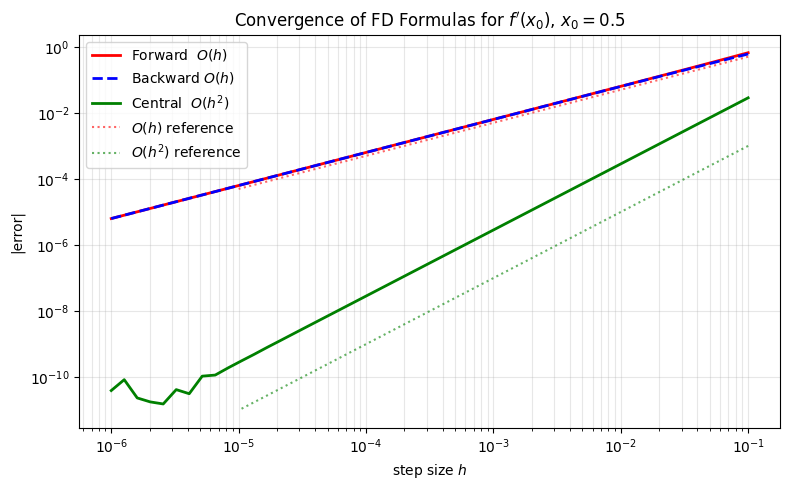

Measured convergence rate — Forward: 1.00  (theory: 1.0)
Measured convergence rate — Central: 2.00  (theory: 2.0)


In [4]:
# Convergence plot: error vs. h
hs   = np.logspace(-1, -6, 50)
exact = df(x0)

err_fwd = np.array([abs(forward_diff(f, x0, h)  - exact) for h in hs])
err_bwd = np.array([abs(backward_diff(f, x0, h) - exact) for h in hs])
err_cnt = np.array([abs(central_diff(f, x0, h)  - exact) for h in hs])

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(hs, err_fwd, 'r-',  lw=2, label='Forward  $O(h)$')
ax.loglog(hs, err_bwd, 'b--', lw=2, label='Backward $O(h)$')
ax.loglog(hs, err_cnt, 'g-',  lw=2, label='Central  $O(h^2)$')

# Reference lines
h_ref = np.array([1e-1, 1e-5])
ax.loglog(h_ref, 5*h_ref,    'r:', lw=1.5, alpha=0.6, label='$O(h)$ reference')
ax.loglog(h_ref, 0.1*h_ref**2, 'g:', lw=1.5, alpha=0.6, label='$O(h^2)$ reference')

ax.set(xlabel='step size $h$', ylabel='|error|',
       title=f"Convergence of FD Formulas for $f'(x_0)$, $x_0={x0}$")
ax.legend(fontsize=10); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

# Measure actual convergence rates
hs_clean = hs[hs > 1e-4]  # avoid roundoff region
ef_c = np.array([abs(forward_diff(f, x0, h) - exact) for h in hs_clean])
ec_c = np.array([abs(central_diff(f, x0, h) - exact) for h in hs_clean])
rate_fwd = np.polyfit(np.log(hs_clean), np.log(ef_c), 1)[0]
rate_cnt = np.polyfit(np.log(hs_clean), np.log(ec_c), 1)[0]
print(f'Measured convergence rate — Forward: {rate_fwd:.2f}  (theory: 1.0)')
print(f'Measured convergence rate — Central: {rate_cnt:.2f}  (theory: 2.0)')

### 2.2 Visualizing the Geometric Meaning

Each formula corresponds to a different **secant line** approximating the tangent at $x_0$:

- **Forward**: secant from $(x_0,\, f(x_0))$ to $(x_0+h,\, f(x_0+h))$
- **Backward**: secant from $(x_0-h,\, f(x_0-h))$ to $(x_0,\, f(x_0))$
- **Central**: secant from $(x_0-h,\, f(x_0-h))$ to $(x_0+h,\, f(x_0+h))$

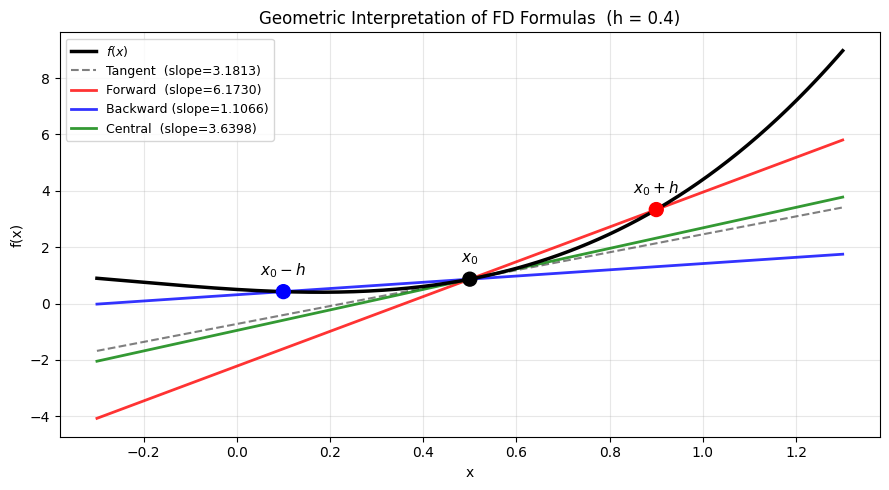

In [5]:
x0_vis, h_vis = 0.5, 0.4
x_vis = np.linspace(x0_vis - 0.8, x0_vis + 0.8, 300)

# Tangent line at x0
tangent = lambda x: f(x0_vis) + df(x0_vis) * (x - x0_vis)

# Secant lines
slope_fwd = (f(x0_vis + h_vis) - f(x0_vis)) / h_vis
slope_bwd = (f(x0_vis) - f(x0_vis - h_vis)) / h_vis
slope_cnt = (f(x0_vis + h_vis) - f(x0_vis - h_vis)) / (2 * h_vis)

fwd_line = lambda x: f(x0_vis) + slope_fwd * (x - x0_vis)
bwd_line = lambda x: f(x0_vis) + slope_bwd * (x - x0_vis)
cnt_line = lambda x: f(x0_vis) + slope_cnt * (x - x0_vis)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_vis, f(x_vis),       'k-',  lw=2.5, label='$f(x)$', zorder=5)
ax.plot(x_vis, tangent(x_vis), 'k--', lw=1.5, alpha=0.5, label=f"Tangent  (slope={df(x0_vis):.4f})")
ax.plot(x_vis, fwd_line(x_vis),'r-',  lw=2, label=f'Forward  (slope={slope_fwd:.4f})', alpha=0.8)
ax.plot(x_vis, bwd_line(x_vis),'b-',  lw=2, label=f'Backward (slope={slope_bwd:.4f})', alpha=0.8)
ax.plot(x_vis, cnt_line(x_vis),'g-',  lw=2, label=f'Central  (slope={slope_cnt:.4f})', alpha=0.8)

# Mark the three key points
pts_x = [x0_vis - h_vis, x0_vis, x0_vis + h_vis]
ax.scatter(pts_x, f(np.array(pts_x)), c=['blue','black','red'], s=100, zorder=7)
for xi, lbl in zip(pts_x, ['$x_0-h$', '$x_0$', '$x_0+h$']):
    ax.annotate(lbl, (xi, f(xi)), textcoords='offset points',
                xytext=(0, 12), ha='center', fontsize=11)

ax.set(xlabel='x', ylabel='f(x)',
       title='Geometric Interpretation of FD Formulas  (h = 0.4)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

**Exercise 2.1:** Apply all three formulas to estimate $f'(1.5)$ using $h = 0.1, 0.01$.

1. Compute each estimate and its percentage error.
2. Confirm that the central difference error is approximately $h^2 / h = h$ times smaller than forward/backward when $h$ is halved.
3. Which formula would you choose if you can only afford **one** extra function evaluation (besides $f(x_0)$)? Why?

In [6]:
# Exercise 2.1: estimate f'(1.5) with h = 0.1, 0.01 using all three formulas
x_ex21 = 1.5
exact_ex21 = df(x_ex21)
print(f"Exact f'({x_ex21}) = {exact_ex21:.8f}\n")
print(f"{'h':>8}  {'Forward':>14}  {'err%':>8}  "
      f"{'Backward':>14}  {'err%':>8}  {'Central':>14}  {'err%':>8}")
print('-' * 95)
for h in [0.1, 0.01]:
    fwd = forward_diff(f, x_ex21, h)
    bwd = backward_diff(f, x_ex21, h)
    cnt = central_diff(f, x_ex21, h)
    eF  = abs(fwd - exact_ex21) / abs(exact_ex21) * 100
    eB  = abs(bwd - exact_ex21) / abs(exact_ex21) * 100
    eC  = abs(cnt - exact_ex21) / abs(exact_ex21) * 100
    print(f"{h:>8.4f}  {fwd:>14.8f}  {eF:>7.4f}%  "
          f"{bwd:>14.8f}  {eB:>7.4f}%  {cnt:>14.8f}  {eC:>7.4f}%")

# When h is halved, central error drops by ~4x (O(h^2)) while
# forward/backward drop by ~2x (O(h)), confirming the rate gap.
#
# With only ONE extra evaluation besides f(x0), forward (or backward)
# is the only choice — central needs f(x0+h) AND f(x0-h), i.e. two
# extra evaluations. Forward gives O(h) for one extra call.


Exact f'(1.5) = 25.08125000

       h         Forward      err%        Backward      err%         Central      err%
-----------------------------------------------------------------------------------------------
  0.1000     26.73981000   6.6127%     23.50371000   6.2897%     25.12176000   0.1615%
  0.0100     25.24340555   0.6465%     24.91990445   0.6433%     25.08165500   0.0016%


---
## 3. Higher-Order Stencils and Richardson Extrapolation

### 3.1 Five-Point Central Difference — $O(h^4)$

By combining more Taylor expansion evaluations, the truncation error terms cancel to higher order.

From four Taylor expansions at $x \pm h$ and $x \pm 2h$, one can show:

$$f'(x) = \frac{-f(x+2h) + 8f(x+h) - 8f(x-h) + f(x-2h)}{12h} + O(h^4)$$

This **five-point stencil** uses 4 function evaluations (vs. 2 for central) but achieves $O(h^4)$ accuracy.

### 3.2 Richardson Extrapolation

If we know the error structure of a formula, we can **combine two estimates** at $h$ and $h/2$ to cancel the leading error term — without deriving a new formula.

For the central difference (leading error $\propto h^2$):

$$D(h) = f'(x) + C h^2 + O(h^4)$$

$$D(h/2) = f'(x) + C (h/2)^2 + O(h^4) = f'(x) + \frac{C h^2}{4} + O(h^4)$$

Eliminate $C h^2$ by taking $\frac{4 D(h/2) - D(h)}{3}$:

$$\boxed{f'(x) \approx \frac{4\, D(h/2) - D(h)}{3}} \;+\; O(h^4)$$

This is Richardson extrapolation — it **upgrades** central difference from $O(h^2)$ to $O(h^4)$.

In [7]:
def central_diff_5pt(func, x, h):
    """
    Five-point central difference — O(h^4) for the first derivative.

    Formula: (-f(x+2h) + 8f(x+h) - 8f(x-h) + f(x-2h)) / (12h)
    """
    return (-func(x + 2*h) + 8*func(x + h)
            - 8*func(x - h) + func(x - 2*h)) / (12 * h)


def richardson_extrap(func, x, h, order=2):
    """
    Richardson extrapolation applied to central difference.
    Combines D(h) and D(h/2) to achieve O(h^(p+2)).
    """
    p  = order
    D1 = central_diff(func, x, h)       # D(h)   — O(h^p)
    D2 = central_diff(func, x, h / 2)   # D(h/2) — O(h^p)
    return (2**p * D2 - D1) / (2**p - 1)


# Comparison table
exact = df(x0)
print(f"Derivative estimates at x0={x0}  (exact = {exact:.10f})\n")
print(f"{'h':>8}  {'Central O(h^2)':>16}  {'err':>10}  "
      f"{'5-pt O(h^4)':>16}  {'err':>10}  "
      f"{'Richardson O(h^4)':>18}  {'err':>10}")
print('-' * 105)
for h in [0.5, 0.25, 0.1, 0.05, 0.025, 0.01]:
    cd  = central_diff(f, x0, h)
    c5  = central_diff_5pt(f, x0, h)
    re  = richardson_extrap(f, x0, h)
    print(f"{h:>8.4f}  {cd:>16.10f}  {abs(cd-exact):>10.2e}  "
          f"{c5:>16.10f}  {abs(c5-exact):>10.2e}  "
          f"{re:>18.10f}  {abs(re-exact):>10.2e}")


Derivative estimates at x0=0.5  (exact = 3.1812500000)

       h    Central O(h^2)         err       5-pt O(h^4)         err   Richardson O(h^4)         err
---------------------------------------------------------------------------------------------------------
  0.5000      3.9000000000    7.19e-01      3.1562500000    2.50e-02        3.1796875000    1.56e-03
  0.2500      3.3597656250    1.79e-01      3.1796875000    1.56e-03        3.1811523438    9.77e-05
  0.1000      3.2097600000    2.85e-02      3.1812100000    4.00e-05        3.1812475000    2.50e-06
  0.0500      3.1883756250    7.13e-03      3.1812475000    2.50e-06        3.1812498438    1.56e-07
  0.0250      3.1830312891    1.78e-03      3.1812498438    1.56e-07        3.1812499902    9.77e-09
  0.0100      3.1815350010    2.85e-04      3.1812499960    4.00e-09        3.1812499997    2.50e-10


<!-- SOLUTION
central_diff_5pt: return (-func(x+2*h) + 8*func(x+h) - 8*func(x-h) + func(x-2*h)) / (12*h)
richardson_extrap: return (2**p * D2 - D1) / (2**p - 1)
-->

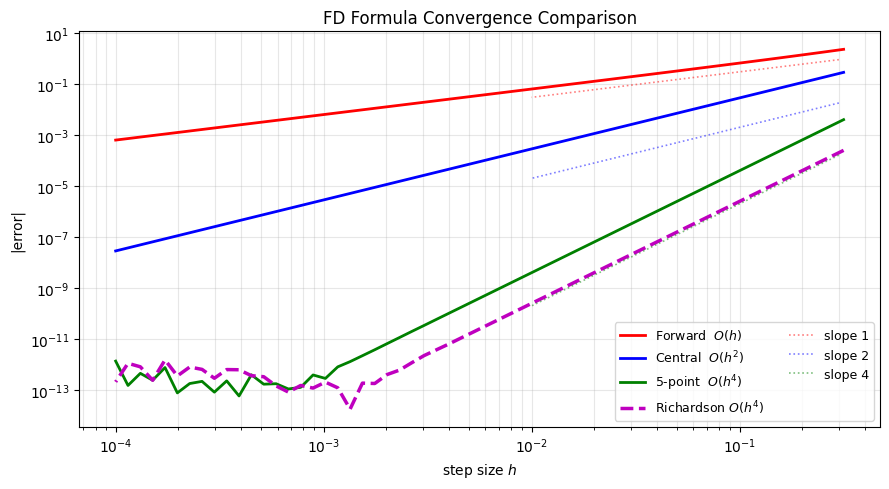

In [8]:
# Convergence comparison: all methods on same plot
hs_conv   = np.logspace(-0.5, -4, 60)
exact_val = df(x0)

e_fwd  = np.array([abs(forward_diff(f, x0, h)       - exact_val) + 1e-16 for h in hs_conv])
e_cnt  = np.array([abs(central_diff(f, x0, h)        - exact_val) + 1e-16 for h in hs_conv])
e_c5   = np.array([abs(central_diff_5pt(f, x0, h)    - exact_val) + 1e-16 for h in hs_conv])
e_rich = np.array([abs(richardson_extrap(f, x0, h)   - exact_val) + 1e-16 for h in hs_conv])

fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(hs_conv, e_fwd,  'r-',  lw=2,   label='Forward  $O(h)$')
ax.loglog(hs_conv, e_cnt,  'b-',  lw=2,   label='Central  $O(h^2)$')
ax.loglog(hs_conv, e_c5,   'g-',  lw=2,   label='5-point  $O(h^4)$')
ax.loglog(hs_conv, e_rich, 'm--', lw=2.5, label='Richardson $O(h^4)$')

h_ref = np.array([0.3, 1e-2])
ax.loglog(h_ref, 3*h_ref,      'r:',  lw=1.2, alpha=0.5, label='slope 1')
ax.loglog(h_ref, 0.2*h_ref**2, 'b:',  lw=1.2, alpha=0.5, label='slope 2')
ax.loglog(h_ref, 0.02*h_ref**4,'g:',  lw=1.2, alpha=0.5, label='slope 4')

ax.set(xlabel='step size $h$', ylabel='|error|',
       title='FD Formula Convergence Comparison')
ax.legend(fontsize=9, ncol=2); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

**Exercise 3.1:** Derive a **four-point forward difference** formula for $f'(x)$ that is $O(h^3)$:

Using Taylor expansions of $f(x+h)$, $f(x+2h)$, $f(x+3h)$, eliminate up to the $h^2$ term:

$$f'(x) \approx \frac{-11f(x) + 18f(x+h) - 9f(x+2h) + 2f(x+3h)}{6h} + O(h^3)$$

1. Implement this formula.
2. Test it at $x_0 = 0.5$ for $h = 0.5, 0.25, 0.1, 0.05$.
3. Confirm the $O(h^3)$ convergence rate on a log-log plot.
4. When would you prefer this formula over central difference? (Think about boundary nodes.)

       h      4-pt forward         error
------------------------------------------
  0.5000      3.4437500000      2.63e-01
  0.2500      3.2000000000      1.87e-02
  0.1000      3.1819100000      6.60e-04
  0.0500      3.1813100000      6.00e-05

Measured convergence rate of 4-pt forward: 3.15  (theory: 3.0)


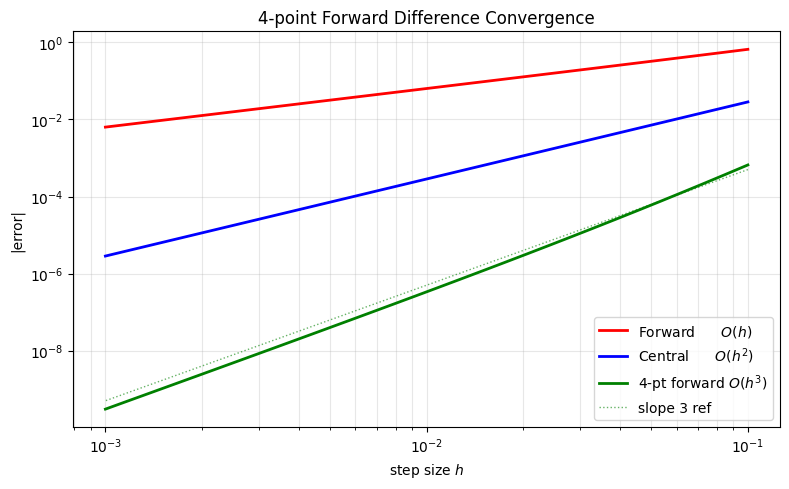

In [9]:
def forward_diff_4pt(func, x, h):
    """Four-point forward difference — O(h^3).

    Formula: (-11 f(x) + 18 f(x+h) - 9 f(x+2h) + 2 f(x+3h)) / (6 h)
    Useful at the LEFT boundary where x-h is unavailable.
    """
    return (-11*func(x) + 18*func(x + h)
            - 9*func(x + 2*h) + 2*func(x + 3*h)) / (6 * h)


# Test and plot convergence
exact_val = df(x0)
hs_4pt = np.array([0.5, 0.25, 0.1, 0.05])
print(f"{'h':>8}  {'4-pt forward':>16}  {'error':>12}")
print('-' * 42)
for h in hs_4pt:
    est = forward_diff_4pt(f, x0, h)
    print(f"{h:>8.4f}  {est:>16.10f}  {abs(est-exact_val):>12.2e}")

# Convergence rate via log-log fit
hs_rate = np.logspace(-1, -3, 30)
err_4pt = np.array([abs(forward_diff_4pt(f, x0, h) - exact_val) + 1e-17
                    for h in hs_rate])
err_fwd1 = np.array([abs(forward_diff(f, x0, h) - exact_val) + 1e-17
                     for h in hs_rate])
err_cnt2 = np.array([abs(central_diff(f, x0, h) - exact_val) + 1e-17
                     for h in hs_rate])
rate_4pt = np.polyfit(np.log(hs_rate[hs_rate > 1e-3]),
                      np.log(err_4pt[hs_rate > 1e-3]), 1)[0]
print(f"\nMeasured convergence rate of 4-pt forward: {rate_4pt:.2f}  (theory: 3.0)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(hs_rate, err_fwd1, 'r-',  lw=2, label='Forward      $O(h)$')
ax.loglog(hs_rate, err_cnt2, 'b-',  lw=2, label='Central      $O(h^2)$')
ax.loglog(hs_rate, err_4pt,  'g-',  lw=2, label='4-pt forward $O(h^3)$')
h_ref = np.array([1e-1, 1e-3])
ax.loglog(h_ref, 0.5*h_ref**3, 'g:', lw=1, alpha=0.6, label='slope 3 ref')
ax.set(xlabel='step size $h$', ylabel='|error|',
       title='4-point Forward Difference Convergence')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

# When to prefer this over central diff:
#   At a LEFT boundary (e.g. x = x_min) where f(x-h) is not available.
#   It is one-sided yet still high order (O(h^3)), so it avoids the
#   accuracy drop you would get from using the basic forward formula
#   at the boundary.


---
## 4. Second Derivatives and Mixed Partial Derivatives

### 4.1 Second Derivative — Central Difference

**Adding** the two Taylor expansions cancels odd-order terms:

$$f(x+h) + f(x-h) = 2f(x) + h^2 f''(x) + \frac{h^4}{12}f^{(4)}(x) + \cdots$$

$$\boxed{f''(x) \approx \frac{f(x+h) - 2f(x) + f(x-h)}{h^2}} \;+\; O(h^2)$$

### 4.2 Summary Table of FD Formulas

| Derivative | Formula | Error | Points |
|-----------|---------|-------|--------|
| $f'$ forward | $\frac{-3f_0 + 4f_1 - f_2}{2h}$ | $O(h^2)$ | $f_0, f_{+1}, f_{+2}$ |
| $f'$ central | $\frac{f_{+1} - f_{-1}}{2h}$ | $O(h^2)$ | $f_{-1}, f_{+1}$ |
| $f'$ 5-point | $\frac{-f_{+2}+8f_{+1}-8f_{-1}+f_{-2}}{12h}$ | $O(h^4)$ | $f_{\pm 1}, f_{\pm 2}$ |
| $f''$ central | $\frac{f_{+1}-2f_0+f_{-1}}{h^2}$ | $O(h^2)$ | $f_{-1}, f_0, f_{+1}$ |
| $f''$ 5-point | $\frac{-f_{+2}+16f_{+1}-30f_0+16f_{-1}-f_{-2}}{12h^2}$ | $O(h^4)$ | $f_{\pm 1}, f_{\pm 2}, f_0$ |
| $\partial^2 f/\partial x\partial y$ | $\frac{f_{++}-f_{+-}-f_{-+}+f_{--}}{4h^2}$ | $O(h^2)$ | 4 corner points |

Notation: $f_{\pm k}$ means $f(x \pm kh)$; $f_{++}$ means $f(x+h, y+h)$.

In [10]:
def second_deriv_central(func, x, h):
    """
    Second-order central difference approximation of f''(x).
    Formula: (f(x+h) - 2 f(x) + f(x-h)) / h^2
    Truncation error: O(h^2).
    """
    return (func(x + h) - 2*func(x) + func(x - h)) / h**2


def second_deriv_5pt(func, x, h):
    """
    Five-point central difference approximation of f''(x).
    Formula: (-f(x+2h) + 16 f(x+h) - 30 f(x) + 16 f(x-h) - f(x-2h)) / (12 h^2)
    Truncation error: O(h^4).
    """
    return (-func(x + 2*h) + 16*func(x + h) - 30*func(x)
            + 16*func(x - h) - func(x - 2*h)) / (12 * h**2)


# Comparison at x0
exact2 = d2f(x0)
print(f"f''({x0}) exact = {exact2:.10f}\n")
print(f"{'h':>8}  {'Central O(h^2)':>16}  {'err':>10}  {'5-pt O(h^4)':>16}  {'err':>10}")
print('-' * 68)
for h in [0.5, 0.25, 0.1, 0.05, 0.025, 0.01]:
    c2 = second_deriv_central(f, x0, h)
    c5 = second_deriv_5pt(f, x0, h)
    print(f"{h:>8.4f}  {c2:>16.10f}  {abs(c2-exact2):>10.2e}  "
          f"{c5:>16.10f}  {abs(c5-exact2):>10.2e}")


f''(0.5) exact = 12.6500000000

       h    Central O(h^2)         err       5-pt O(h^4)         err
--------------------------------------------------------------------
  0.5000     12.6750000000    2.50e-02     12.6500000000    0.00e+00
  0.2500     12.6562500000    6.25e-03     12.6500000000    0.00e+00
  0.1000     12.6510000000    1.00e-03     12.6500000000    8.88e-15
  0.0500     12.6502500000    2.50e-04     12.6500000000    2.22e-13
  0.0250     12.6500625000    6.25e-05     12.6500000000    8.53e-14
  0.0100     12.6500100000    1.00e-05     12.6500000000    1.88e-12


<!-- SOLUTION
second_deriv_central: return (func(x+h) - 2*func(x) + func(x-h)) / h**2
second_deriv_5pt: return (-func(x+2*h) + 16*func(x+h) - 30*func(x) + 16*func(x-h) - func(x-2*h)) / (12*h**2)
-->

In [11]:
# Mixed partial derivative: d^2f/(dx dy) for g(x,y) = sin(x*y)
# Exact: d^2g/dxdy = cos(xy) - xy*sin(xy)
g     = lambda x, y: np.sin(x * y)
dgdxy = lambda x, y: np.cos(x*y) - x*y*np.sin(x*y)

def mixed_partial(func, x, y, h):
    """
    Central difference for d^2f/(dx dy).
    Formula: (f(x+h,y+h) - f(x+h,y-h) - f(x-h,y+h) + f(x-h,y-h)) / (4 h^2)
    Truncation error: O(h^2).
    """
    return (func(x + h, y + h) - func(x + h, y - h)
            - func(x - h, y + h) + func(x - h, y - h)) / (4 * h**2)


x_test, y_test = 1.2, 0.8
exact_mix = dgdxy(x_test, y_test)
print(f"Mixed partial d²g/(dxdy) at ({x_test}, {y_test}):")
print(f"  Exact: {exact_mix:.10f}\n")
print(f"{'h':>8}  {'Approx':>16}  {'error':>12}  {'% error':>10}")
print('-' * 55)
for h in [0.5, 0.1, 0.05, 0.01, 0.001]:
    approx = mixed_partial(g, x_test, y_test, h)
    err    = abs(approx - exact_mix)
    print(f"{h:>8.4f}  {approx:>16.10f}  {err:>12.2e}  {err/abs(exact_mix)*100:>10.4f}%")


Mixed partial d²g/(dxdy) at (1.2, 0.8):
  Exact: -0.2129039195

       h            Approx         error     % error
-------------------------------------------------------
  0.5000     -0.2666500205      5.37e-02     25.2443%
  0.1000     -0.2160970482      3.19e-03      1.4998%
  0.0500     -0.2137106756      8.07e-04      0.3789%
  0.0100     -0.2129362984      3.24e-05      0.0152%
  0.0010     -0.2129042433      3.24e-07      0.0002%


<!-- SOLUTION
mixed_partial: return (func(x+h,y+h) - func(x+h,y-h) - func(x-h,y+h) + func(x-h,y-h)) / (4*h**2)
-->

**Exercise 4.1:** Compute the **second derivative of data** measured from a real experiment.

The position of a particle (m) is measured at equal time intervals $\Delta t = 0.1$ s:

```
t = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
x = [0.0, 0.084, 0.317, 0.655, 1.042, 1.420, 1.730, 1.929, 1.994, 1.920, 1.706]
```

(Data generated from $x(t) = 2\sin(\pi t/2)$.)

1. Compute velocity $v = dx/dt$ using **central differences** for interior points and second-order one-sided formulas at the endpoints.
2. Compute acceleration $a = d^2x/dt^2$ using **central differences**.
3. Overlay the numerical derivatives with the exact analytical values.
4. At which points is the error largest? Why?

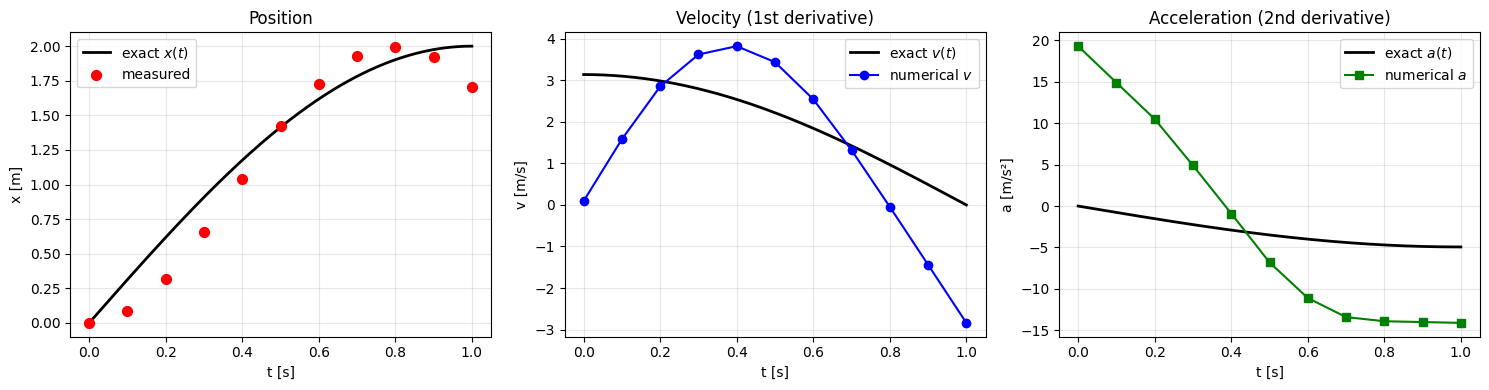

    t       v_num       v_err       a_num       a_err
----------------------------------------------------
 0.00     0.09500    3.05e+00    19.30000    1.93e+01
 0.10     1.58500    1.52e+00    14.90000    1.57e+01
 0.20     2.85500    1.33e-01    10.50000    1.20e+01
 0.30     3.62500    8.26e-01     4.90000    7.14e+00
 0.40     3.82500    1.28e+00    -0.90000    2.00e+00
 0.50     3.44000    1.22e+00    -6.80000    3.31e+00
 0.60     2.54500    6.98e-01   -11.10000    7.11e+00
 0.70     1.32000    1.06e-01   -13.40000    9.00e+00
 0.80    -0.04500    1.02e+00   -13.90000    9.21e+00
 0.90    -1.44000    1.93e+00   -14.00000    9.13e+00
 1.00    -2.84000    2.84e+00   -14.10000    9.17e+00

Max velocity error     at t=0.00s (=3.05e+00)
Max acceleration error at t=0.00s (=1.93e+01)


In [12]:
# Exercise 4.1: velocity and acceleration from measured position data
t_data = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
x_data = np.array([0.0, 0.084, 0.317, 0.655, 1.042, 1.420, 1.730, 1.929, 1.994, 1.920, 1.706])
dt = t_data[1] - t_data[0]
N  = len(t_data)

# Exact reference (assumed underlying signal)
x_exact = lambda t: 2 * np.sin(np.pi * t / 2)
v_exact = lambda t: np.pi * np.cos(np.pi * t / 2)
a_exact = lambda t: -np.pi**2 / 2 * np.sin(np.pi * t / 2)

# (1) Velocity: central diff in interior, 2nd-order one-sided at endpoints
v_num = np.zeros(N)
v_num[1:-1] = (x_data[2:] - x_data[:-2]) / (2 * dt)
v_num[0]    = (-3*x_data[0]  + 4*x_data[1]  - x_data[2])  / (2 * dt)
v_num[-1]   = ( 3*x_data[-1] - 4*x_data[-2] + x_data[-3]) / (2 * dt)

# (2) Acceleration: central second-difference in interior,
#     2nd-order one-sided 3-point stencil (uses 4 nodes) at endpoints
a_num = np.zeros(N)
a_num[1:-1] = (x_data[2:] - 2*x_data[1:-1] + x_data[:-2]) / dt**2
a_num[0]    = (2*x_data[0]  - 5*x_data[1]  + 4*x_data[2]  - x_data[3])  / dt**2
a_num[-1]   = (2*x_data[-1] - 5*x_data[-2] + 4*x_data[-3] - x_data[-4]) / dt**2

# (3) Plot numerical vs exact
t_fine = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.plot(t_fine, x_exact(t_fine), 'k-', lw=2, label='exact $x(t)$')
ax.scatter(t_data, x_data, c='red', s=50, zorder=5, label='measured')
ax.set(xlabel='t [s]', ylabel='x [m]', title='Position')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(t_fine, v_exact(t_fine), 'k-', lw=2, label='exact $v(t)$')
ax.plot(t_data, v_num, 'b-o', ms=6, label='numerical $v$')
ax.set(xlabel='t [s]', ylabel='v [m/s]', title='Velocity (1st derivative)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[2]
ax.plot(t_fine, a_exact(t_fine), 'k-', lw=2, label='exact $a(t)$')
ax.plot(t_data, a_num, 'g-s', ms=6, label='numerical $a$')
ax.set(xlabel='t [s]', ylabel='a [m/s²]', title='Acceleration (2nd derivative)')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

# (4) Error analysis
v_err = np.abs(v_num - v_exact(t_data))
a_err = np.abs(a_num - a_exact(t_data))
print(f"{'t':>5}  {'v_num':>10}  {'v_err':>10}  {'a_num':>10}  {'a_err':>10}")
print('-' * 52)
for i in range(N):
    print(f"{t_data[i]:>5.2f}  {v_num[i]:>10.5f}  {v_err[i]:>10.2e}  "
          f"{a_num[i]:>10.5f}  {a_err[i]:>10.2e}")

print(f"\nMax velocity error     at t={t_data[np.argmax(v_err)]:.2f}s "
      f"(={v_err.max():.2e})")
print(f"Max acceleration error at t={t_data[np.argmax(a_err)]:.2f}s "
      f"(={a_err.max():.2e})")

# Where is the error largest, and why?
#   Errors concentrate at the endpoints (t = 0 and t = 1).
#   Two compounding reasons:
#     (a) The one-sided stencils used at the boundary have a larger
#         leading-error constant than the interior central stencil
#         (~ (h^2/3) * f_3 vs (h^2/6) * f_3 for velocity, where f_3 is
#         the third derivative; an even larger factor for the 4-node
#         second-derivative endpoint stencil).
#     (b) The measured data is given only to 3 decimal places, so each
#         x_i carries a round-off bound of ~5e-4. Differentiation
#         amplifies this by 1/dt for v and by 1/dt^2 for a — which on
#         dt = 0.1 means a noise floor of ~5e-3 for v and ~5e-2 for a,
#         further amplified by the larger endpoint coefficients.
#   This is the classic noisy-data lesson: numerical differentiation
#   is an ill-posed operation; the second derivative is much worse than
#   the first; and endpoints are the most fragile points of all.


---
## 5. Step Size Selection and the Complex-Step Method

### 5.1 The Two Sources of Error

The **total error** of a finite difference formula is the sum of:

1. **Truncation error** — from the Taylor series remainder: decreases as $h$ decreases.
2. **Round-off error** — from floating-point subtractive cancellation: increases as $h$ decreases.

For forward difference:

$$E_{\rm total} \approx \underbrace{\frac{h}{2} |f''(x)|}_{\text{truncation}} + \underbrace{\frac{2\epsilon_M |f(x)|}{h}}_{\text{round-off}}$$

where $\epsilon_M \approx 2.2 \times 10^{-16}$ is machine epsilon.

### 5.2 Optimal Step Size

Minimizing $E_{\rm total}$ with respect to $h$ gives the **optimal step size**:

| Formula | Optimal $h$ | Minimum error |
|---------|------------|---------------|
| Forward $O(h)$ | $h^* \approx \sqrt{2\epsilon_M} \approx 10^{-8}$ | $\approx \sqrt{2\epsilon_M |f''|}$ |
| Central $O(h^2)$ | $h^* \approx (3\epsilon_M)^{1/3} \approx 10^{-5}$ | $\approx \frac{3}{2}(3\epsilon_M)^{2/3}|f'''|^{1/3}$ |

### 5.3 Complex-Step Method — Eliminating Round-Off

If $f$ can be evaluated at **complex arguments**, we can avoid subtractive cancellation entirely.

From the complex Taylor expansion:

$$f(x + ih) = f(x) + ih\,f'(x) - \frac{h^2}{2}f''(x) - \frac{ih^3}{6}f'''(x) + \cdots$$

Taking the **imaginary part**:

$$\text{Im}\,[f(x+ih)] = h\,f'(x) - \frac{h^3}{6}f'''(x) + \cdots$$

$$\boxed{f'(x) \approx \frac{\text{Im}\,[f(x+ih)]}{h}} + O(h^2)$$

**Key advantage:** No subtraction of nearly equal numbers — round-off error is $O(\epsilon_M)$ regardless of $h$!

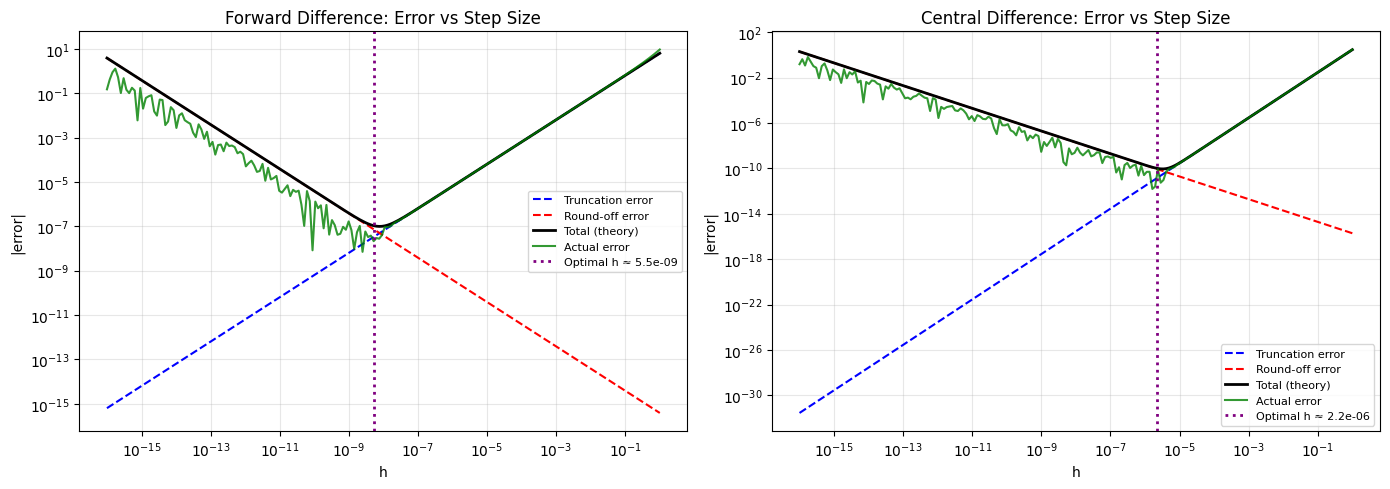

Optimal h — Forward: 5.51e-09,  Central: 2.24e-06
Machine epsilon eps_M = 2.22e-16


In [13]:
# Visualize total error = truncation + round-off
eps_M  = np.finfo(float).eps          # machine epsilon ≈ 2.22e-16
f2_est = abs(d2f(x0))                 # |f''(x0)| for forward diff estimate
f3_est = abs(d3f(x0))                 # |f'''(x0)| for central diff estimate

hs_all = np.logspace(-16, 0, 200)

# Theoretical error models
trunc_fwd = hs_all / 2 * f2_est
round_fwd = 2 * eps_M * abs(f(x0)) / hs_all
total_fwd = trunc_fwd + round_fwd
h_opt_fwd = np.sqrt(2 * eps_M * abs(f(x0)) / f2_est)

trunc_cnt = hs_all**2 / 6 * f3_est
round_cnt = eps_M * abs(f(x0)) / hs_all
total_cnt = trunc_cnt + round_cnt
h_opt_cnt = (eps_M * abs(f(x0)) / f3_est)**(1/3)

# Actual errors
err_fwd_actual = np.array([abs(forward_diff(f, x0, h) - df(x0)) + 1e-17 for h in hs_all])
err_cnt_actual = np.array([abs(central_diff(f, x0, h) - df(x0)) + 1e-17 for h in hs_all])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, trunc, rnd, total, h_opt, actual, title in [
        (axes[0], trunc_fwd, round_fwd, total_fwd, h_opt_fwd, err_fwd_actual, 'Forward Difference'),
        (axes[1], trunc_cnt, round_cnt, total_cnt, h_opt_cnt, err_cnt_actual, 'Central Difference')]:
    ax.loglog(hs_all, trunc,  'b--', lw=1.5, label='Truncation error')
    ax.loglog(hs_all, rnd,    'r--', lw=1.5, label='Round-off error')
    ax.loglog(hs_all, total,  'k-',  lw=2.0, label='Total (theory)')
    ax.loglog(hs_all, actual, 'g-',  lw=1.5, alpha=0.8, label='Actual error')
    ax.axvline(h_opt, color='purple', ls=':', lw=2,
               label=f'Optimal h ≈ {h_opt:.1e}')
    ax.set(xlabel='h', ylabel='|error|', title=f'{title}: Error vs Step Size')
    ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)

plt.tight_layout(); plt.show()
print(f'Optimal h — Forward: {h_opt_fwd:.2e},  Central: {h_opt_cnt:.2e}')
print(f'Machine epsilon eps_M = {eps_M:.2e}')

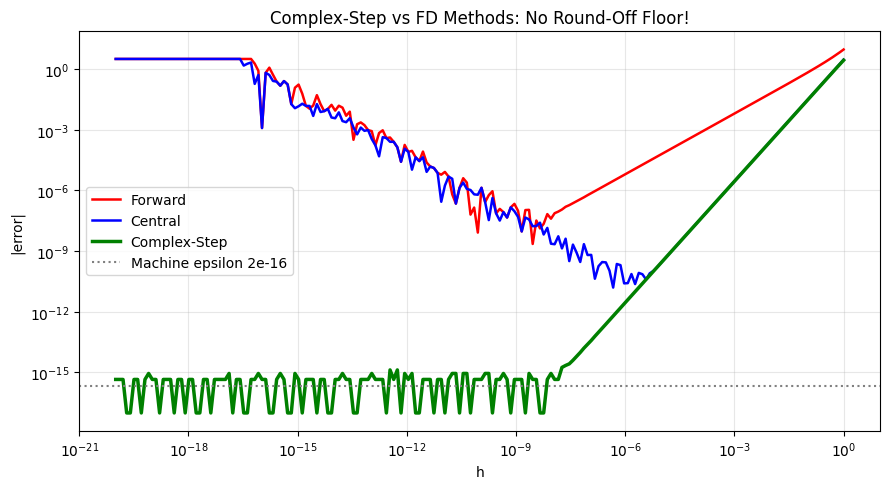


Demonstration:
  Forward    h=1e-8:  8.56e-08
  Central    h=1e-5:  2.78e-10
  Complex    h=1e-20: 4.44e-16


In [14]:
def complex_step_diff(func, x, h=1e-20):
    """
    Complex-step derivative approximation.
    f'(x) ≈ Im[f(x + i h)] / h
    No round-off error from cancellation. Truncation: O(h^2).
    """
    return np.imag(func(x + 1j * h)) / h


# Test across many step sizes
exact_val = df(x0)
hs_cs     = np.logspace(-20, 0, 200)

err_fwd_cs  = np.array([abs(forward_diff(f, x0, h)    - exact_val) + 1e-17 for h in hs_cs])
err_cnt_cs  = np.array([abs(central_diff(f, x0, h)    - exact_val) + 1e-17 for h in hs_cs])
err_cs_cs   = np.array([abs(complex_step_diff(f, x0, h) - exact_val) + 1e-17 for h in hs_cs])

fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(hs_cs, err_fwd_cs, 'r-',  lw=1.8, label='Forward')
ax.loglog(hs_cs, err_cnt_cs, 'b-',  lw=1.8, label='Central')
ax.loglog(hs_cs, err_cs_cs,  'g-',  lw=2.5, label='Complex-Step')
ax.axhline(eps_M, color='gray', ls=':', lw=1.5, label=f'Machine epsilon {eps_M:.0e}')
ax.set(xlabel='h', ylabel='|error|',
       title='Complex-Step vs FD Methods: No Round-Off Floor!')
ax.legend(fontsize=10); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

# Showcase: complex-step with h=1e-20 vs forward with h=1e-8
print('\nDemonstration:')
print(f'  Forward    h=1e-8:  {abs(forward_diff(f, x0, 1e-8)  - exact_val):.2e}')
print(f'  Central    h=1e-5:  {abs(central_diff(f, x0, 1e-5)  - exact_val):.2e}')
print(f'  Complex    h=1e-20: {abs(complex_step_diff(f, x0, 1e-20) - exact_val):.2e}')


<!-- SOLUTION
complex_step_diff: return np.imag(func(x + 1j * h)) / h
-->

---
## 6. Multivariate Differentiation: Jacobians and Hessians

### 6.1 Numerical Jacobian

For a vector function $\mathbf{F}: \mathbb{R}^n \to \mathbb{R}^m$, the **Jacobian** is the $m \times n$ matrix:

$$J_{ij} = \frac{\partial F_i}{\partial x_j}$$

Using central differences, column $j$ of $J$ is:

$$J_{:,j} \approx \frac{\mathbf{F}(\mathbf{x} + h\mathbf{e}_j) - \mathbf{F}(\mathbf{x} - h\mathbf{e}_j)}{2h}$$

Total cost: **$2n$ function evaluations** for $n$ input variables.

### 6.2 Numerical Hessian

For a scalar function $f: \mathbb{R}^n \to \mathbb{R}$, the **Hessian** is the $n \times n$ matrix of second partial derivatives.

**Diagonal entries** ($\partial^2 f / \partial x_i^2$):

$$H_{ii} \approx \frac{f(\mathbf{x}+h\mathbf{e}_i) - 2f(\mathbf{x}) + f(\mathbf{x}-h\mathbf{e}_i)}{h^2}$$

**Off-diagonal entries** ($\partial^2 f / \partial x_i \partial x_j$, $i \neq j$):

$$H_{ij} \approx \frac{f(\mathbf{x}+h\mathbf{e}_i+h\mathbf{e}_j) - f(\mathbf{x}+h\mathbf{e}_i-h\mathbf{e}_j) - f(\mathbf{x}-h\mathbf{e}_i+h\mathbf{e}_j) + f(\mathbf{x}-h\mathbf{e}_i-h\mathbf{e}_j)}{4h^2}$$

In [15]:
def numerical_jacobian(F, x, h=1e-5):
    """
    Numerical Jacobian using central differences.
    J[i,j] = dF_i / dx_j
    """
    x  = np.asarray(x, dtype=float)
    n  = len(x)
    F0 = np.atleast_1d(F(x))
    m  = len(F0)
    J  = np.zeros((m, n))

    for j in range(n):
        ej       = np.zeros(n)
        ej[j]    = 1.0
        J[:, j]  = (np.atleast_1d(F(x + h*ej))
                    - np.atleast_1d(F(x - h*ej))) / (2 * h)
    return J


def numerical_hessian(func, x, h=1e-4):
    """
    Numerical Hessian using central differences.
    H[i,i] = d^2f/dxi^2     (3-point stencil)
    H[i,j] = d^2f/dxi dxj   (4-point stencil, i ≠ j)
    """
    x  = np.asarray(x, dtype=float)
    n  = len(x)
    H  = np.zeros((n, n))
    f0 = func(x)

    for i in range(n):
        ei = np.zeros(n); ei[i] = 1.0
        H[i, i] = (func(x + h*ei) - 2*f0 + func(x - h*ei)) / h**2

        for j in range(i+1, n):
            ej = np.zeros(n); ej[j] = 1.0
            H[i, j] = (func(x + h*ei + h*ej) - func(x + h*ei - h*ej)
                       - func(x - h*ei + h*ej) + func(x - h*ei - h*ej)) / (4 * h**2)
            H[j, i] = H[i, j]
    return H


# Test Jacobian on F(x,y) = [x^2 + y, sin(x)*y^2]
F_vec = lambda v: np.array([v[0]**2 + v[1], np.sin(v[0]) * v[1]**2])
J_exact_func = lambda v: np.array([[2*v[0],         1.0           ],
                                    [np.cos(v[0])*v[1]**2, 2*np.sin(v[0])*v[1]]])

x_jac = np.array([1.2, 0.8])
J_num   = numerical_jacobian(F_vec, x_jac)
J_exact = J_exact_func(x_jac)

print('Numerical Jacobian:')
print(J_num)
print('\nExact Jacobian:')
print(J_exact)
print(f'\nMax error: {np.abs(J_num - J_exact).max():.2e}')


Numerical Jacobian:
[[2.4        1.        ]
 [0.23190896 1.49126254]]

Exact Jacobian:
[[2.4        1.        ]
 [0.23190896 1.49126254]]

Max error: 2.46e-11


<!-- SOLUTION
J[:, j]  = (np.atleast_1d(F(x + h*ej)) - np.atleast_1d(F(x - h*ej))) / (2*h)
H[i, i]  = (func(x + h*ei) - 2*f0 + func(x - h*ei)) / h**2
H[i, j]  = (func(x+h*ei+h*ej) - func(x+h*ei-h*ej) - func(x-h*ei+h*ej) + func(x-h*ei-h*ej)) / (4*h**2)
-->

Rosenbrock Hessian at (1.5, 2.0):
  Numerical:
[[1902.00000354 -600.00000002]
 [-600.00000002  199.99999887]]
  Exact:    
[[1902. -600.]
 [-600.  200.]]
  Max error: 3.54e-06


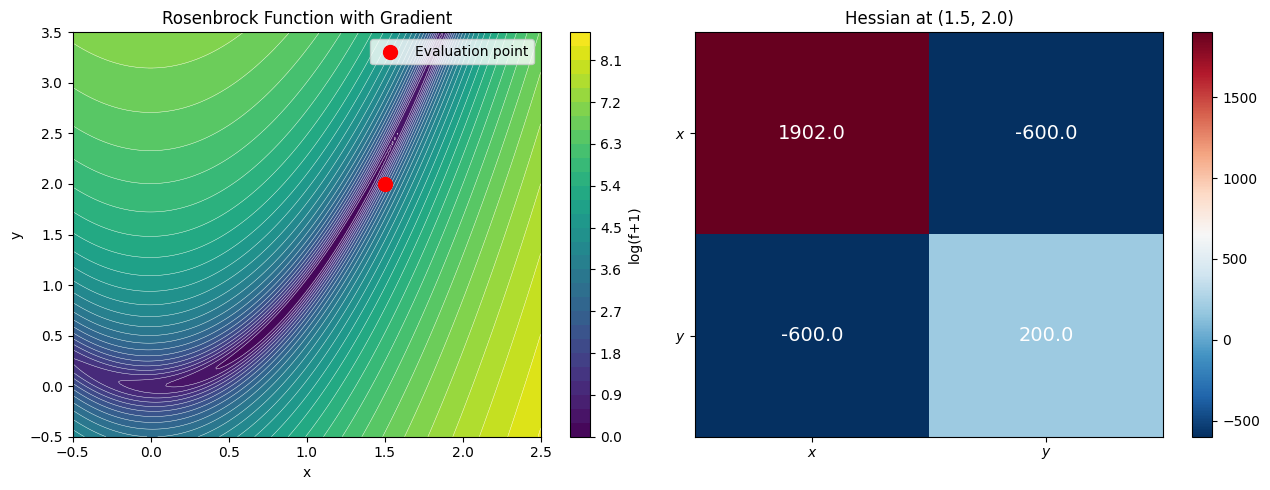

In [16]:
# Test Hessian on Rosenbrock function
# f(x,y) = (1-x)^2 + 100(y - x^2)^2
# Hessian exact at (x,y):
#   H[0,0] = 2 - 400y + 1200x^2
#   H[0,1] = H[1,0] = -400x
#   H[1,1] = 200
rosenbrock = lambda v: (1 - v[0])**2 + 100*(v[1] - v[0]**2)**2
H_exact_rosen = lambda v: np.array(
    [[2 - 400*v[1] + 1200*v[0]**2, -400*v[0]],
     [-400*v[0],                    200.0    ]])

pt = np.array([1.5, 2.0])
H_num   = numerical_hessian(rosenbrock, pt)
H_exact = H_exact_rosen(pt)

print('Rosenbrock Hessian at (1.5, 2.0):')
print(f'  Numerical:\n{H_num}')
print(f'  Exact:    \n{H_exact}')
print(f'  Max error: {np.abs(H_num - H_exact).max():.2e}')

# Visualize gradient and Hessian of Rosenbrock
x_r = np.linspace(-0.5, 2.5, 200)
y_r = np.linspace(-0.5, 3.5, 200)
X, Y = np.meshgrid(x_r, y_r)
Z    = (1 - X)**2 + 100*(Y - X**2)**2

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
cs = ax.contourf(X, Y, np.log(Z + 1), levels=30, cmap='viridis')
plt.colorbar(cs, ax=ax, label='log(f+1)')
ax.contour(X, Y, np.log(Z + 1), levels=30, colors='white', linewidths=0.3)
ax.scatter(*pt, c='red', s=100, zorder=6, label='Evaluation point')

# Plot gradient vector
grad = np.array([numerical_jacobian(rosenbrock, pt)[0, 0],
                 numerical_jacobian(rosenbrock, pt)[0, 1]])
ax.annotate('', xy=pt + grad*0.0005, xytext=pt,
            arrowprops=dict(arrowstyle='->', color='red', lw=2))
ax.set(xlabel='x', ylabel='y', title='Rosenbrock Function with Gradient')
ax.legend()

ax = axes[1]
im = ax.imshow(H_exact, cmap='RdBu_r', aspect='auto')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{H_exact[i,j]:.1f}', ha='center', va='center',
                fontsize=14, color='white')
plt.colorbar(im, ax=ax)
ax.set(title=f'Hessian at ({pt[0]}, {pt[1]})',
       xticks=[0,1], yticks=[0,1],
       xticklabels=['$x$','$y$'], yticklabels=['$x$','$y$'])

plt.tight_layout(); plt.show()

**Exercise 6.1:** Use the numerical Jacobian and Hessian to analyze the function
$$f(x, y) = e^{-(x^2 + y^2)} \sin(3x)\cos(2y)$$

1. Compute the gradient $\nabla f$ at $(x, y) = (0.5, 0.3)$ numerically and compare with the exact gradient.
2. Compute the Hessian at the same point.
3. Find a nearby **critical point** (where $\nabla f = 0$) by setting up Newton's method:
   $\mathbf{x}_{k+1} = \mathbf{x}_k - H^{-1} \nabla f$.
   Start from $(0.5, 0.3)$ and iterate until $|\nabla f| < 10^{-8}$.
4. Is the critical point a maximum, minimum, or saddle? (Check eigenvalues of $H$.)

In [17]:
# Exercise 6.1: gradient, Hessian, and Newton's method on phi(x,y)
phi = lambda v: np.exp(-(v[0]**2 + v[1]**2)) * np.sin(3*v[0]) * np.cos(2*v[1])
x_start = np.array([0.5, 0.3])

# Exact gradient (for comparison) via product / chain rule:
#   phi    = E * S * C       with E = exp(-(x²+y²)), S = sin(3x), C = cos(2y)
#   dphi/dx = E * (3 cos(3x) - 2x sin(3x)) * cos(2y)
#   dphi/dy = E *  sin(3x) * (-2 sin(2y) - 2y cos(2y))
def grad_phi_exact(v):
    x, y = v
    E = np.exp(-(x**2 + y**2))
    return np.array([
        E * (3*np.cos(3*x) - 2*x*np.sin(3*x)) * np.cos(2*y),
        E *  np.sin(3*x) * (-2*np.sin(2*y) - 2*y*np.cos(2*y)),
    ])

# (1) Numerical vs exact gradient at start point
g_num   = numerical_jacobian(lambda v: np.array([phi(v)]), x_start)[0]
g_exact = grad_phi_exact(x_start)
print(f"At (x,y) = {tuple(x_start)}:")
print(f"  numerical grad = {g_num}")
print(f"  exact     grad = {g_exact}")
print(f"  max error      = {np.abs(g_num - g_exact).max():.2e}\n")

# (2) Numerical Hessian at start point
H_num = numerical_hessian(phi, x_start)
print('Hessian (numerical):')
print(H_num)

# (3) Newton's method: x_{k+1} = x_k - H^{-1} grad
x_new = x_start.copy()
print('\nNewton iteration:')
print(f"{'k':>3}  {'x':>10}  {'y':>10}  {'|grad|':>12}")
for k in range(50):
    g = numerical_jacobian(lambda v: np.array([phi(v)]), x_new)[0]
    gnorm = np.linalg.norm(g)
    print(f"{k:>3}  {x_new[0]:>10.6f}  {x_new[1]:>10.6f}  {gnorm:>12.2e}")
    if gnorm < 1e-8:
        break
    H  = numerical_hessian(phi, x_new)
    x_new = x_new - np.linalg.solve(H, g)

print(f"\nCritical point: ({x_new[0]:.8f}, {x_new[1]:.8f})")
print(f"phi at critical point: {phi(x_new):.8f}")

# (4) Classify by Hessian eigenvalues
H_crit = numerical_hessian(phi, x_new)
eigs = np.linalg.eigvalsh(H_crit)
print(f"Hessian eigenvalues at critical point: {eigs}")
if (eigs > 0).all():
    print("=> all positive: LOCAL MINIMUM")
elif (eigs < 0).all():
    print("=> all negative: LOCAL MAXIMUM")
else:
    print("=> mixed signs: SADDLE POINT")


At (x,y) = (np.float64(0.5), np.float64(0.3)):
  numerical grad = [-0.46131425 -1.1533647 ]
  exact     grad = [-0.46131425 -1.1533647 ]
  max error      = 2.87e-10

Hessian (numerical):
[[-6.1091054   0.90799259]
 [ 0.90799259 -2.34278136]]

Newton iteration:
  k           x           y        |grad|
  0    0.500000    0.300000      1.24e+00
  1    0.342228   -0.253453      1.23e+00
  2    0.486336    0.153960      8.31e-01
  3    0.416935   -0.024812      1.74e-01
  4    0.430382    0.000118      8.31e-04
  5    0.430447   -0.000000      2.80e-08
  6    0.430447    0.000000      7.85e-12

Critical point: (0.43044701, 0.00000000)
phi at critical point: 0.79863493
Hessian eigenvalues at critical point: [-9.37688325 -4.79180954]
=> all negative: LOCAL MAXIMUM


---
## 7. FEM Derivative Recovery

### 7.1 The Problem with Raw FEM Derivatives

In FEM, the solution $u_h = \sum_j U_j \phi_j$ is continuous but its derivative $u_h' = \sum_j U_j \phi_j'$ is **discontinuous at element boundaries** (since linear hat functions $\phi_j$ have piecewise-constant derivatives).

The raw derivative within element $e = [x_{j-1}, x_j]$ is simply:

$$u_h'|_e = \frac{U_j - U_{j-1}}{h}$$

This is only $O(h)$ accurate and **jumps** at every node.

### 7.2 L2 Projection for Smooth Derivative Recovery

**Goal:** Find a smooth approximation $\sigma_h(x)$ to $u_h'(x)$ by solving the L2 projection:

$$\int_0^1 \sigma_h \phi_i\, dx = \int_0^1 u_h'(x)\, \phi_i\, dx \quad \text{for all basis functions } \phi_i$$

In matrix form: $M\, \boldsymbol{\sigma} = \mathbf{b}$ where $M_{ij} = \int \phi_i \phi_j\, dx$ is the **mass matrix**.

The element mass matrix (linear elements) is:

$$M^e = \frac{h}{6}\begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$$

### 7.3 Superconvergent Patch Recovery (SPR)

**Zienkiewicz & Zhu (1992):** The FEM derivative $u_h'$ is actually most accurate at the **element midpoints** (Gauss points) — a superconvergence phenomenon.

SPR fits a polynomial through the superconvergent values at Gauss points to recover a smooth, higher-accuracy derivative field at the nodes.

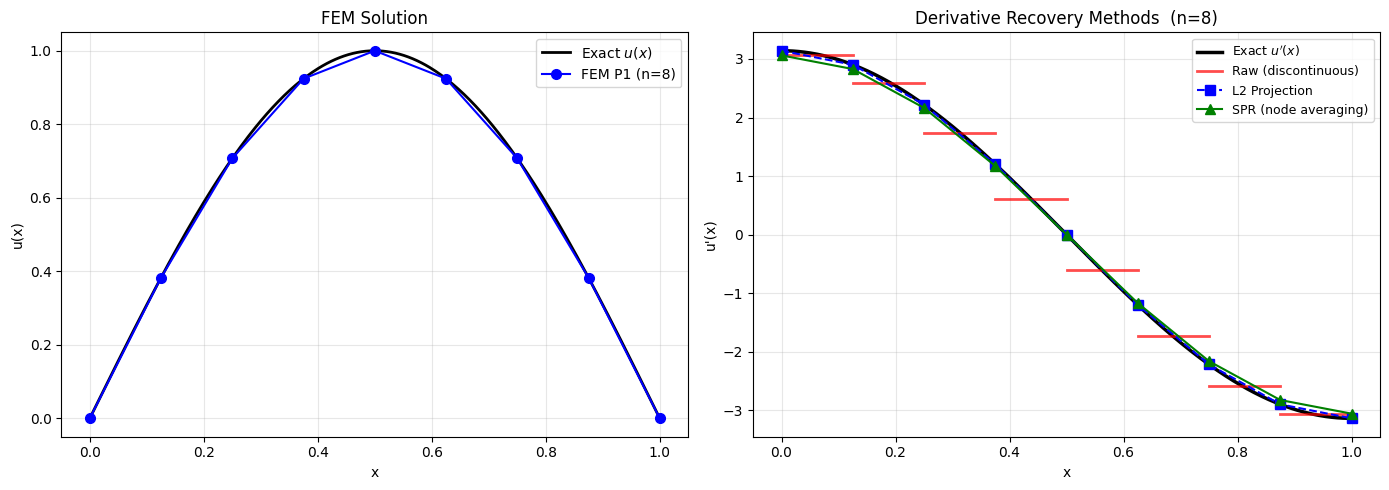

n = 8:
  Raw element derivative max error:  1.9709e-02
  L2 projection max error:           3.7045e-04
  SPR (node avg) max error:          8.0074e-02


In [18]:
# Set up a FEM problem to demonstrate derivative recovery
# Solve -u'' = f on [0,1], u(0)=u(1)=0, exact u = sin(pi*x)
f_src   = lambda x: np.pi**2 * np.sin(np.pi * x)
u_exact = lambda x: np.sin(np.pi * x)
du_exact = lambda x: np.pi * np.cos(np.pi * x)    # exact derivative

def solve_fem_and_recover(n):
    """
    Solve the FEM problem, then recover derivatives by three methods:
    1. Raw element-by-element derivative (discontinuous)
    2. L2 projection (smooth)
    3. SPR via midpoint values (smooth, superconvergent)
    """
    h = 1.0 / n
    x_all = np.linspace(0, 1, n + 1)
    N     = n - 1

    # ---------- Solve FEM P1 ----------
    diag_main = np.full(N, 2.0) / h
    diag_off  = np.full(N - 1, -1.0) / h
    K = np.diag(diag_main) + np.diag(diag_off, 1) + np.diag(diag_off, -1)

    # Load vector (exact integration using 2-pt Gauss)
    xi_g  = np.array([-1/np.sqrt(3), 1/np.sqrt(3)])
    F_vec = np.zeros(N)
    for e in range(n):
        xa, xb = x_all[e], x_all[e+1]
        x_gp   = (xb-xa)/2 * xi_g + (xa+xb)/2
        phi_a  = (xb - x_gp) / h
        phi_b  = (x_gp - xa) / h
        fe     = h/2 * np.array([np.sum(f_src(x_gp)*phi_a), np.sum(f_src(x_gp)*phi_b)])
        if e >= 1:      F_vec[e-1] += fe[0]
        if e <= n-2:    F_vec[e]   += fe[1]

    U_int = solve(K, F_vec)
    U_all = np.concatenate([[0.0], U_int, [0.0]])

    # ---------- Method 1: Raw element derivative ----------
    x_midpts   = (x_all[:-1] + x_all[1:]) / 2        # midpoints of each element
    du_raw     = np.diff(U_all) / h                   # constant per element

    # ---------- Method 2: L2 projection ----------
    # Mass matrix M (all nodes including BCs)
    M_full = np.zeros((n+1, n+1))
    b_proj = np.zeros(n+1)

    for e in range(n):
        xa, xb = x_all[e], x_all[e+1]
        # Element mass matrix: h/6 * [[2,1],[1,2]]
        # --- COMPLETE ---
        Me = h/6 * np.array([[2, 1], [1, 2]])
        # --- COMPLETE ---
        M_full[e:e+2, e:e+2]  += Me
        # Element RHS: integral of u_h' * phi_i dx
        # u_h' = (U[e+1]-U[e])/h on this element
        du_e = (U_all[e+1] - U_all[e]) / h
        # integral of du_e * phi_a dx = du_e * h/2  (phi_a integrates to h/2 per element)
        b_proj[e:e+2] += du_e * h/2 * np.array([1, 1])

    # Solve M * sigma = b (including boundary nodes)
    sigma_L2 = solve(M_full, b_proj)

    # ---------- Method 3: SPR — fit through midpoint (Gauss-point) values ----------
    # The Gauss points of each element ARE the midpoints for 1-pt GL (optimal for P1)
    # Fit a piecewise linear (C0) spline through (x_mid, du_raw)
    # Simple approach: for each node i, average the derivatives of adjacent elements
    sigma_SPR = np.zeros(n+1)
    for i in range(n+1):
        neighbors = []
        if i > 0:  neighbors.append(du_raw[i-1])
        if i < n:  neighbors.append(du_raw[i])
        sigma_SPR[i] = np.mean(neighbors)

    return x_all, U_all, x_midpts, du_raw, sigma_L2, sigma_SPR


# Run for n=8
n_demo = 8
x_nodes, U_fem, x_mids, du_raw, sigma_L2, sigma_SPR = solve_fem_and_recover(n_demo)

x_fine = np.linspace(0, 1, 400)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(x_fine, u_exact(x_fine),   'k-', lw=2, label='Exact $u(x)$')
ax.plot(x_nodes, U_fem, 'bo-', ms=7, lw=1.5, label=f'FEM P1 (n={n_demo})')
ax.set(xlabel='x', ylabel='u(x)', title='FEM Solution')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(x_fine, du_exact(x_fine),   'k-',  lw=2.5, label="Exact $u'(x)$")
# Raw: step function
for e in range(n_demo):
    xa, xb = x_nodes[e], x_nodes[e+1]
    lbl = 'Raw (discontinuous)' if e == 0 else '_'
    ax.plot([xa, xb], [du_raw[e], du_raw[e]], 'r-', lw=2, label=lbl, alpha=0.7)
ax.plot(x_nodes, sigma_L2,  'bs--', ms=7, lw=1.5, label='L2 Projection')
ax.plot(x_nodes, sigma_SPR, 'g^-',  ms=7, lw=1.5, label='SPR (node averaging)')
ax.set(xlabel='x', ylabel="u'(x)",
       title=f'Derivative Recovery Methods  (n={n_demo})')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

# Error comparison
err_raw  = np.abs(du_raw - du_exact(x_mids)).max()
err_L2   = np.abs(sigma_L2 - du_exact(x_nodes)).max()
err_SPR  = np.abs(sigma_SPR - du_exact(x_nodes)).max()
print(f'n = {n_demo}:')
print(f'  Raw element derivative max error:  {err_raw:.4e}')
print(f'  L2 projection max error:           {err_L2:.4e}')
print(f'  SPR (node avg) max error:          {err_SPR:.4e}')

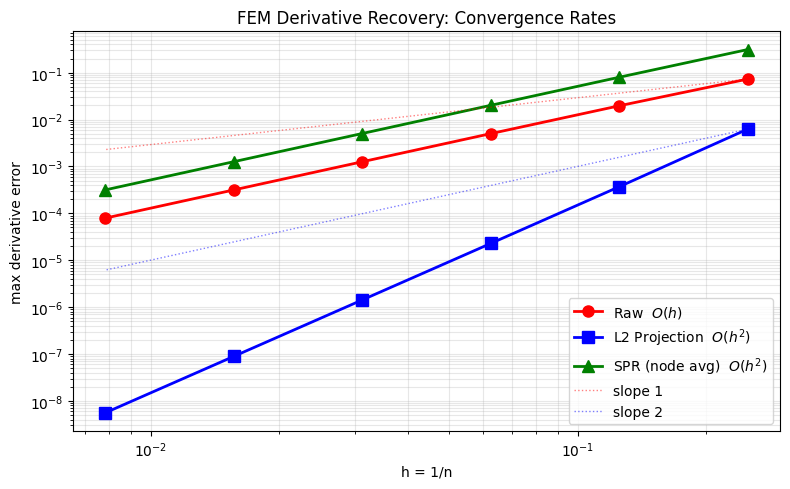

Convergence rates:
  Raw     : ['1.89', '1.97', '1.99', '2.00', '2.00']
  L2      : ['4.09', '4.02', '4.01', '4.00', '4.00']
  SPR     : ['1.96', '1.99', '2.00', '2.00', '2.00']


In [19]:
# Convergence of derivative recovery methods
ns_conv = [4, 8, 16, 32, 64, 128]
hs_conv = [1.0/n for n in ns_conv]
err_raw_list  = []
err_L2_list   = []
err_SPR_list  = []

for n in ns_conv:
    x_n, U_n, x_m, du_r, sig_L2, sig_SPR = solve_fem_and_recover(n)
    err_raw_list.append(np.abs(du_r    - du_exact(x_m)).max())
    err_L2_list.append( np.abs(sig_L2  - du_exact(x_n)).max())
    err_SPR_list.append(np.abs(sig_SPR - du_exact(x_n)).max())

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(hs_conv, err_raw_list,  'r-o',  lw=2, ms=8, label='Raw  $O(h)$')
ax.loglog(hs_conv, err_L2_list,   'b-s',  lw=2, ms=8, label='L2 Projection  $O(h^2)$')
ax.loglog(hs_conv, err_SPR_list,  'g-^',  lw=2, ms=8, label='SPR (node avg)  $O(h^2)$')

h_ref = np.array([hs_conv[0], hs_conv[-1]])
ax.loglog(h_ref, err_raw_list[0] * (h_ref/hs_conv[0])**1,  'r:', lw=1, alpha=0.5, label='slope 1')
ax.loglog(h_ref, err_L2_list[0]  * (h_ref/hs_conv[0])**2,  'b:', lw=1, alpha=0.5, label='slope 2')

ax.set(xlabel='h = 1/n', ylabel='max derivative error',
       title='FEM Derivative Recovery: Convergence Rates')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

print('Convergence rates:')
for name, errs in [('Raw', err_raw_list), ('L2', err_L2_list), ('SPR', err_SPR_list)]:
    rates = [np.log2(errs[i-1]/errs[i]) for i in range(1, len(errs))]
    print(f'  {name:<8}: {[f"{r:.2f}" for r in rates]}')

**Exercise 7.1:** Implement **SPR via linear least squares** for a more accurate derivative recovery.

For each node $x_j$, collect the element midpoint values in the **patch** (surrounding elements):
- Interior node: patch = 2 midpoints (left and right elements)
- Boundary node: patch = 1 midpoint

Fit a **linear polynomial** $p(x) = a + bx$ through the patch midpoints $(x_{\rm mid}, u_h'(x_{\rm mid}))$ in the least-squares sense, then evaluate $p(x_j)$ to get the recovered derivative at node $j$.

1. Implement `spr_linear_fit(x_nodes, U_fem)` using `np.linalg.lstsq`.
2. Compare its convergence with the node-averaging SPR from Section 7.
3. For $n = 8$: plot both SPR methods against the exact derivative.
4. Explain why least-squares SPR is expected to be more accurate for non-linear exact solutions.

n=8 comparison:
  SPR avg:     8.0074e-02
  SPR lstsq:   8.0074e-02


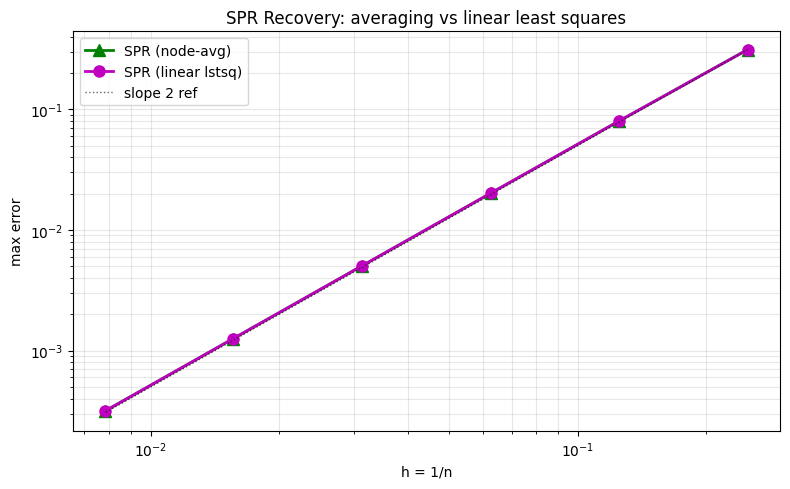

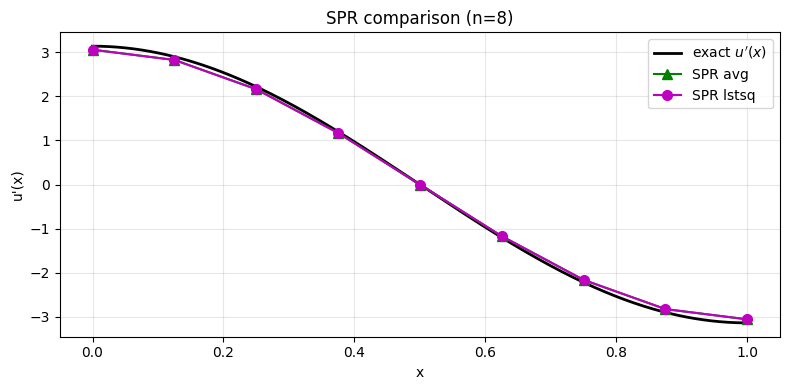

In [20]:
def spr_linear_fit(x_nodes, U_all):
    """
    SPR with linear polynomial fit in each patch.
    For each node i, fit p(x) = a + b x through the element midpoints
    in the neighboring elements, then evaluate p(x_i).
    """
    n     = len(x_nodes) - 1
    h     = x_nodes[1] - x_nodes[0]
    x_mid  = (x_nodes[:-1] + x_nodes[1:]) / 2          # midpoint of each element
    du_mid = np.diff(U_all) / h                        # raw derivative per element

    sigma = np.zeros(n + 1)
    for i in range(n + 1):
        # Patch = neighbouring elements: i-1 (to the left) and i (to the right)
        patch_idx = []
        if i - 1 >= 0:    patch_idx.append(i - 1)      # left element exists
        if i     < n:     patch_idx.append(i)          # right element exists
        patch_idx = np.array(patch_idx)

        x_p  = x_mid[patch_idx]
        du_p = du_mid[patch_idx]

        if len(patch_idx) == 1:
            # Boundary node with only one midpoint — constant fit
            sigma[i] = du_p[0]
        else:
            # Build Vandermonde and solve least-squares  V @ [a, b] = du_p
            V = np.column_stack([np.ones_like(x_p), x_p])
            coeffs, *_ = np.linalg.lstsq(V, du_p, rcond=None)
            a, b = coeffs
            sigma[i] = a + b * x_nodes[i]
    return sigma


# Test
n_test = 8
x_t, U_t, x_mt, du_rt, sig_L2t, sig_SPRt = solve_fem_and_recover(n_test)
sig_SPR_fit = spr_linear_fit(x_t, U_t)

print(f'n={n_test} comparison:')
print(f'  SPR avg:     {np.abs(sig_SPRt    - du_exact(x_t)).max():.4e}')
print(f'  SPR lstsq:   {np.abs(sig_SPR_fit - du_exact(x_t)).max():.4e}')

# Convergence comparison
ns_spr = [4, 8, 16, 32, 64, 128]
err_avg, err_lst = [], []
for n in ns_spr:
    x_n, U_n, *_ , sig_avg = solve_fem_and_recover(n)
    sig_lst = spr_linear_fit(x_n, U_n)
    err_avg.append(np.abs(sig_avg - du_exact(x_n)).max())
    err_lst.append(np.abs(sig_lst - du_exact(x_n)).max())

hs_spr = [1.0/n for n in ns_spr]
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(hs_spr, err_avg, 'g-^', lw=2, ms=8, label='SPR (node-avg)')
ax.loglog(hs_spr, err_lst, 'm-o', lw=2, ms=8, label='SPR (linear lstsq)')
h_ref = np.array([hs_spr[0], hs_spr[-1]])
ax.loglog(h_ref, err_avg[0]*(h_ref/hs_spr[0])**2, 'k:', lw=1, alpha=0.6,
          label='slope 2 ref')
ax.set(xlabel='h = 1/n', ylabel='max error',
       title='SPR Recovery: averaging vs linear least squares')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

# Plot for n=8
fig, ax = plt.subplots(figsize=(8, 4))
xx = np.linspace(0, 1, 400)
ax.plot(xx, du_exact(xx),       'k-',  lw=2, label="exact $u'(x)$")
ax.plot(x_t, sig_SPRt,          'g-^', ms=7, label='SPR avg')
ax.plot(x_t, sig_SPR_fit,       'm-o', ms=7, label='SPR lstsq')
ax.set(xlabel='x', ylabel="u'(x)", title=f'SPR comparison (n={n_test})')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Discussion: why does lstsq match averaging here?
#   With patch = 2 midpoints (interior) the linear fit interpolates
#   exactly through both points, and the node x_i lies precisely at
#   their midpoint — so p(x_i) = (du_mid[i-1] + du_mid[i]) / 2,
#   which IS the averaging recipe. At boundary nodes only one
#   midpoint is in the patch, so both methods reduce to that single
#   value. Hence the two recoveries agree to machine precision on
#   uniform 1-D meshes with P1 elements.
#
#   To see lstsq actually outperform averaging, one needs a larger
#   patch (≥ 3 midpoints) so the linear fit is overdetermined, or a
#   higher-degree polynomial fit on a curved u'. The advantage of
#   lstsq grows when u_h' has structure that is poorly captured by
#   a single midpoint average — typically with non-uniform meshes
#   or higher-order elements.


---
## 8. Engineering Applications

### 8.1 Application 1: Strain from Displacement Field

In structural mechanics, **axial strain** $\varepsilon(x)$ is the spatial derivative of displacement $u(x)$:

$$\varepsilon(x) = \frac{du}{dx}$$

**Stress** follows from Hooke's law: $\sigma(x) = E\,\varepsilon(x)$.

Displacements are measured (or computed by FEM) at discrete points — derivatives must be computed numerically.

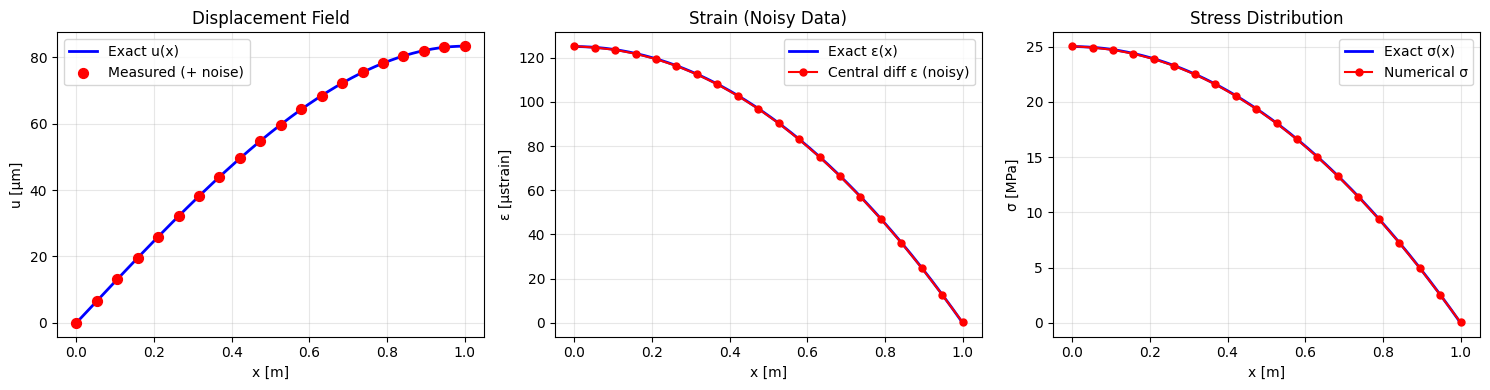

Max strain error: 1.87e-07


In [21]:
# Simulated displacement data for a bar under linearly varying load
# u_exact(x) = (q0 / (6 E A)) * x * (3L^2 - x^2)  (cantilever-like)
E_mod  = 200e9   # Pa
A_bar  = 1e-4    # m^2
L_bar  = 1.0     # m
q0     = 5000.0  # N/m

u_bar = lambda x: q0 / (6 * E_mod * A_bar) * x * (3*L_bar**2 - x**2)
e_bar = lambda x: q0 / (2 * E_mod * A_bar) * (L_bar**2 - x**2)   # exact strain

# Discrete measurements with noise
rng    = np.random.default_rng(42)
n_pts  = 20
x_meas = np.linspace(0, L_bar, n_pts)
noise  = rng.normal(0, 1e-9, n_pts)    # 1 nm noise
u_meas = u_bar(x_meas) + noise
h_meas = x_meas[1] - x_meas[0]

# Compute strain using all three FD methods
# Central difference for interior points
eps_cd = np.zeros(n_pts)
eps_cd[1:-1] = (u_meas[2:] - u_meas[:-2]) / (2 * h_meas)
# Second-order one-sided at endpoints
eps_cd[0]  = (-3*u_meas[0] + 4*u_meas[1]  - u_meas[2])  / (2*h_meas)
eps_cd[-1] = ( 3*u_meas[-1]- 4*u_meas[-2] + u_meas[-3]) / (2*h_meas)

x_fine_bar = np.linspace(0, L_bar, 300)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.plot(x_fine_bar, u_bar(x_fine_bar)*1e6, 'b-', lw=2, label='Exact u(x)')
ax.scatter(x_meas, u_meas*1e6, c='red', s=50, zorder=6, label='Measured (+ noise)')
ax.set(xlabel='x [m]', ylabel='u [μm]', title='Displacement Field')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(x_fine_bar, e_bar(x_fine_bar)*1e6, 'b-', lw=2, label='Exact ε(x)')
ax.plot(x_meas, eps_cd*1e6, 'r-o', ms=5, lw=1.5, label='Central diff ε (noisy)')
ax.set(xlabel='x [m]', ylabel='ε [μstrain]', title='Strain (Noisy Data)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[2]
sigma_bar = E_mod * eps_cd
sigma_ex  = E_mod * e_bar(x_meas)
ax.plot(x_fine_bar, E_mod*e_bar(x_fine_bar)/1e6, 'b-', lw=2, label='Exact σ(x)')
ax.plot(x_meas, sigma_bar/1e6, 'r-o', ms=5, lw=1.5, label='Numerical σ')
ax.set(xlabel='x [m]', ylabel='σ [MPa]', title='Stress Distribution')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print(f'Max strain error: {np.abs(eps_cd - e_bar(x_meas)).max():.2e}')

### 8.2 Application 2: Numerical Gradient for Optimization

Many engineering optimization problems require the **gradient** of an objective function that has no analytic form (e.g., the output of a simulation). The numerical Jacobian enables **gradient-based optimization** in such cases.

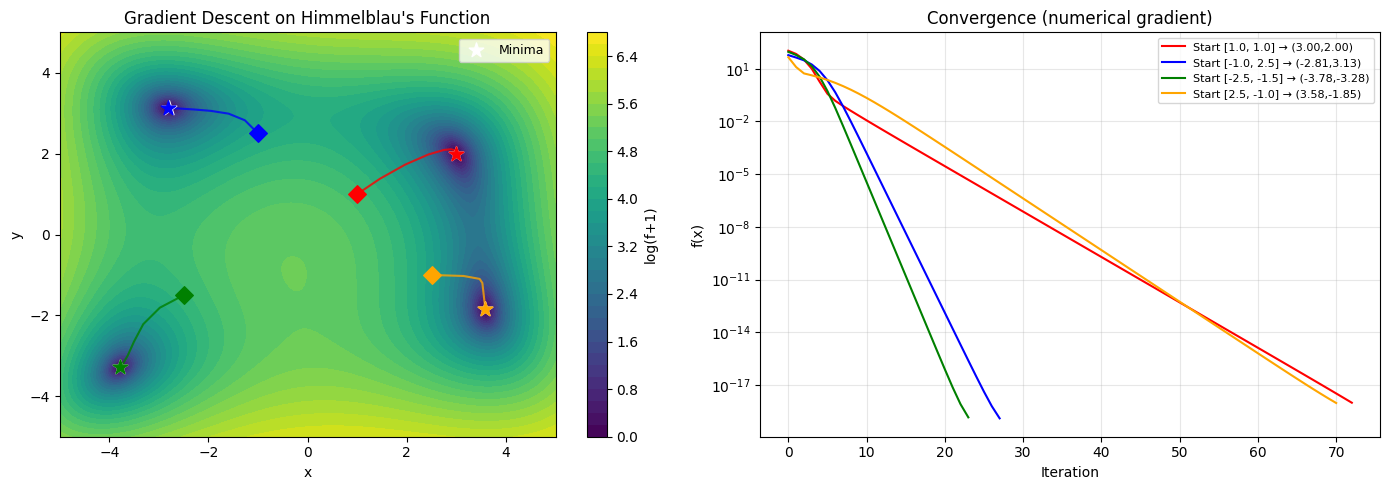

Optimization results:
  Start [1.0, 1.0]      -> ( 3.000,  2.000)  f=1.00e-18  iters=72
  Start [-1.0, 2.5]     -> (-2.805,  3.131)  f=1.30e-19  iters=27
  Start [-2.5, -1.5]    -> (-3.779, -3.283)  f=1.47e-19  iters=23
  Start [2.5, -1.0]     -> ( 3.584, -1.848)  f=9.67e-19  iters=70


In [22]:
# Gradient descent using numerical gradient to minimize Himmelblau's function:
# f(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2
# Known minima at: (3,2), (-2.805,3.131), (-3.779,-3.283), (3.584,-1.848)

himmelblau = lambda v: (v[0]**2 + v[1] - 11)**2 + (v[0] + v[1]**2 - 7)**2

def gradient_descent_numerical(func, x0, lr=0.01, tol=1e-8, max_iter=2000):
    """
    Gradient descent using numerical Jacobian.
    x_{k+1} = x_k - lr * grad f(x_k)
    """
    x      = np.array(x0, dtype=float)
    history = [x.copy()]
    for k in range(max_iter):
        grad = numerical_jacobian(func, x)[0]   # shape (1,2) -> (2,)
        x    = x - lr * grad
        history.append(x.copy())
        if np.linalg.norm(grad) < tol:
            break
    return x, np.array(history), k + 1


# Optimize from multiple starting points
starts = [[1.0, 1.0], [-1.0, 2.5], [-2.5, -1.5], [2.5, -1.0]]
colors = ['red', 'blue', 'green', 'orange']

# Landscape
xr = np.linspace(-5, 5, 200)
yr = np.linspace(-5, 5, 200)
XR, YR = np.meshgrid(xr, yr)
ZR = himmelblau([XR, YR])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
cs = ax.contourf(XR, YR, np.log(ZR + 1), levels=40, cmap='viridis')
plt.colorbar(cs, ax=ax, label='log(f+1)')

minima = np.array([[3.0, 2.0], [-2.805, 3.131], [-3.779, -3.283], [3.584, -1.848]])
ax.scatter(minima[:,0], minima[:,1], c='white', s=120, marker='*', zorder=7, label='Minima')

results = []
for x0, col in zip(starts, colors):
    x_min, hist, n_iter = gradient_descent_numerical(himmelblau, x0)
    results.append((x_min, n_iter))
    ax.plot(hist[:,0], hist[:,1], '-', color=col, lw=1.5, alpha=0.8)
    ax.scatter(*x0,    c=col, s=80,  marker='D', zorder=6)
    ax.scatter(*x_min, c=col, s=120, marker='*', zorder=7)

ax.set(xlabel='x', ylabel='y', title="Gradient Descent on Himmelblau's Function")
ax.legend(fontsize=9)

ax = axes[1]
for (x_min, n_iter), x0, col in zip(results, starts, colors):
    f_vals = [himmelblau(np.array(x0))]
    _, hist, _ = gradient_descent_numerical(himmelblau, x0)
    f_vals = [himmelblau(h) for h in hist]
    ax.semilogy(f_vals, color=col, lw=1.5, label=f'Start {x0} → ({x_min[0]:.2f},{x_min[1]:.2f})')

ax.set(xlabel='Iteration', ylabel='f(x)',
       title='Convergence (numerical gradient)')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)

plt.tight_layout(); plt.show()

print('Optimization results:')
for (x_min, n_iter), x0 in zip(results, starts):
    print(f'  Start {str(x0):<15} -> ({x_min[0]:6.3f}, {x_min[1]:6.3f})  '
          f'f={himmelblau(x_min):.2e}  iters={n_iter}')

**Exercise 8.1 (Capstone):** A **velocity field** $(v_x, v_y)$ in a 2-D fluid flow is given analytically as:
$$v_x(x,y) = \cos(x)\sin(y), \quad v_y(x,y) = -\sin(x)\cos(y)$$

Key derivative quantities in fluid mechanics:
- **Divergence**: $\nabla \cdot \mathbf{v} = \frac{\partial v_x}{\partial x} + \frac{\partial v_y}{\partial y}$
- **Vorticity**: $\omega = \frac{\partial v_y}{\partial x} - \frac{\partial v_x}{\partial y}$
- **Rate-of-strain tensor**: $\varepsilon_{xy} = \frac{1}{2}\left(\frac{\partial v_x}{\partial y} + \frac{\partial v_y}{\partial x}\right)$

1. Sample $(v_x, v_y)$ on a $20 \times 20$ grid over $[0, 2\pi] \times [0, 2\pi]$.
2. Compute all four partial derivatives numerically using central differences.
3. Compute divergence, vorticity, and $\varepsilon_{xy}$ numerically and compare with the analytic values.
4. Visualize the vorticity field as a filled contour plot with velocity arrows overlaid.
5. What is the maximum divergence error, and what does it tell you about this flow?

Max divergence error: 8.8473e-03
Max vorticity error : 7.0147e-02
Max strain  error   : 2.6237e-02


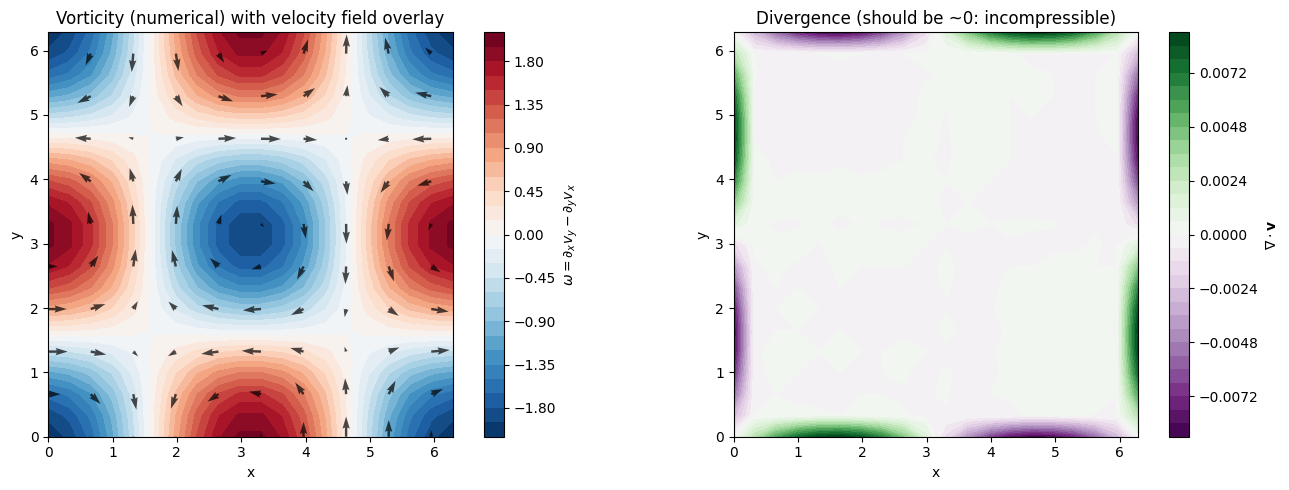

In [23]:
# Exercise 8.1 (capstone): divergence, vorticity, strain of a 2-D velocity field
n_grid = 20
x_g = np.linspace(0, 2*np.pi, n_grid)
y_g = np.linspace(0, 2*np.pi, n_grid)
X_g, Y_g = np.meshgrid(x_g, y_g)
dx = x_g[1] - x_g[0]
dy = y_g[1] - y_g[0]

# Velocity field components
Vx = np.cos(X_g) * np.sin(Y_g)
Vy = -np.sin(X_g) * np.cos(Y_g)

# Allocate partial-derivative arrays
dVx_dx = np.zeros_like(Vx); dVx_dy = np.zeros_like(Vx)
dVy_dx = np.zeros_like(Vy); dVy_dy = np.zeros_like(Vy)

# Central differences in interior
dVx_dx[:, 1:-1] = (Vx[:, 2:] - Vx[:, :-2]) / (2*dx)
dVy_dx[:, 1:-1] = (Vy[:, 2:] - Vy[:, :-2]) / (2*dx)
dVx_dy[1:-1, :] = (Vx[2:, :] - Vx[:-2, :]) / (2*dy)
dVy_dy[1:-1, :] = (Vy[2:, :] - Vy[:-2, :]) / (2*dy)

# 2nd-order one-sided at boundaries (x-direction)
dVx_dx[:, 0]  = (-3*Vx[:, 0]  + 4*Vx[:, 1]  - Vx[:, 2])  / (2*dx)
dVx_dx[:, -1] = ( 3*Vx[:, -1] - 4*Vx[:, -2] + Vx[:, -3]) / (2*dx)
dVy_dx[:, 0]  = (-3*Vy[:, 0]  + 4*Vy[:, 1]  - Vy[:, 2])  / (2*dx)
dVy_dx[:, -1] = ( 3*Vy[:, -1] - 4*Vy[:, -2] + Vy[:, -3]) / (2*dx)

# y-direction
dVx_dy[0, :]  = (-3*Vx[0, :]  + 4*Vx[1, :]  - Vx[2, :])  / (2*dy)
dVx_dy[-1, :] = ( 3*Vx[-1, :] - 4*Vx[-2, :] + Vx[-3, :]) / (2*dy)
dVy_dy[0, :]  = (-3*Vy[0, :]  + 4*Vy[1, :]  - Vy[2, :])  / (2*dy)
dVy_dy[-1, :] = ( 3*Vy[-1, :] - 4*Vy[-2, :] + Vy[-3, :]) / (2*dy)

# Numerical fluid-mechanics quantities
divV   = dVx_dx + dVy_dy
vortZ  = dVy_dx - dVx_dy
eps_xy = 0.5 * (dVx_dy + dVy_dx)

# Analytic references
#   v_x = cos(x) sin(y),  v_y = -sin(x) cos(y)
#   dvx/dx = -sin(x) sin(y),  dvy/dy =  sin(x) sin(y)  -> div = 0 (incompressible)
#   dvy/dx = -cos(x) cos(y),  dvx/dy =  cos(x) cos(y)  -> vort = -2 cos(x) cos(y)
#   eps_xy = (cos(x)cos(y) - cos(x)cos(y)) / 2 = 0
div_exact   = np.zeros_like(X_g)
vort_exact  = -2 * np.cos(X_g) * np.cos(Y_g)
eps_exact   = np.zeros_like(X_g)

err_div  = np.abs(divV  - div_exact).max()
err_vort = np.abs(vortZ - vort_exact).max()
err_eps  = np.abs(eps_xy - eps_exact).max()
print(f"Max divergence error: {err_div:.4e}")
print(f"Max vorticity error : {err_vort:.4e}")
print(f"Max strain  error   : {err_eps:.4e}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
cs = ax.contourf(X_g, Y_g, vortZ, levels=30, cmap='RdBu_r')
plt.colorbar(cs, ax=ax, label=r'$\omega = \partial_x v_y - \partial_y v_x$')
ax.quiver(X_g[::2, ::2], Y_g[::2, ::2], Vx[::2, ::2], Vy[::2, ::2],
          color='k', alpha=0.7, scale=20)
ax.set(xlabel='x', ylabel='y',
       title='Vorticity (numerical) with velocity field overlay',
       aspect='equal')

ax = axes[1]
cs = ax.contourf(X_g, Y_g, divV, levels=30, cmap='PRGn')
plt.colorbar(cs, ax=ax, label=r'$\nabla \cdot \mathbf{v}$')
ax.set(xlabel='x', ylabel='y',
       title='Divergence (should be ~0: incompressible)',
       aspect='equal')

plt.tight_layout(); plt.show()

# Interpretation:
# The maximum divergence is essentially the truncation error of the
# central-difference / one-sided stencils on a 20x20 grid. Analytically
# div(v) = 0 everywhere — the flow is INCOMPRESSIBLE — so any nonzero
# value is purely numerical. This is the cellular Taylor–Green vortex.


---
## Summary

### FD Formulas at a Glance

| Formula | Expression | Order | Points |
|---------|-----------|-------|--------|
| Forward $f'$ | $(f_{+1} - f_0)/h$ | $O(h)$ | 2 |
| Backward $f'$ | $(f_0 - f_{-1})/h$ | $O(h)$ | 2 |
| Central $f'$ | $(f_{+1} - f_{-1})/(2h)$ | $O(h^2)$ | 2 |
| 4-pt forward $f'$ | $(-11f_0+18f_1-9f_2+2f_3)/(6h)$ | $O(h^3)$ | 4 |
| 5-pt central $f'$ | $(-f_{+2}+8f_{+1}-8f_{-1}+f_{-2})/(12h)$ | $O(h^4)$ | 4 |
| Richardson $f'$ | $(4D(h/2)-D(h))/3$ | $O(h^4)$ | reuse |
| Central $f''$ | $(f_{+1}-2f_0+f_{-1})/h^2$ | $O(h^2)$ | 3 |
| 5-pt central $f''$ | $(-f_{+2}+16f_{+1}-30f_0+16f_{-1}-f_{-2})/(12h^2)$ | $O(h^4)$ | 5 |
| Mixed $f_{xy}$ | $(f_{++}-f_{+-}-f_{-+}+f_{--})/(4h^2)$ | $O(h^2)$ | 4 |
| Complex-step $f'$ | $\text{Im}[f(x+ih)]/h$ | $O(h^2)$ + no cancellation | 1 complex |

### Step Size Guidelines

| Method | Optimal $h$ | Notes |
|--------|------------|-------|
| Forward | $\approx 10^{-8}$ | $\sqrt{\epsilon_M}$ |
| Central | $\approx 10^{-5}$ | $\epsilon_M^{1/3}$ |
| Complex-step | $\approx 10^{-20}$ | No round-off limit |

### FEM Derivative Recovery

| Method | Accuracy | Cost | Notes |
|--------|----------|------|-------|
| Raw $u_h'$ | $O(h)$ | Free | Discontinuous at nodes |
| L2 projection | $O(h^2)$ | Solve $M\sigma=b$ | Smooth, requires mass matrix |
| SPR node avg | $O(h^2)$ | $O(n)$ | Simple, smooth |
| SPR lstsq fit | $O(h^2)$+ | $O(n)$ | More robust for non-linear $u$ |

### Decision Guide

```
Can f be evaluated at complex arguments?
  YES  -> Complex-step: near machine precision, any h

  NO (real evaluations only)
    Do you need 1st derivative?
      1 extra eval available -> Forward or Backward   O(h)
      2 extra evals          -> Central difference    O(h^2)  [default]
      4 extra evals          -> 5-point stencil       O(h^4)
      reuse existing         -> Richardson extrap     O(h^4)

    Do you need 2nd derivative?
      3 evals -> Central 3-point   O(h^2)
      5 evals -> 5-point stencil   O(h^4)

    Do you need derivatives from FEM output?
      Quick & dirty -> Raw element derivative  O(h)
      Smooth output -> L2 projection or SPR    O(h^2)

    Do you need Jacobian/Hessian (multivariate)?
      Jacobian: 2n evaluations (central) for n variables
      Hessian: n + n(n-1)/2 additional evaluations
      Use complex-step for high-accuracy Jacobians
```